In [3]:
# For four datasets
import os
import sys
import time
import glob
import random
import argparse

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

from Helper_Scripts.calculate_metrics import (
    summarize_all_metrics,
    WINDOW as LOCAL_WINDOW,
    CWC_ETA,
)

from Helper_Scripts.models_TLMR import LSTMQuantileReg

# ============================================================
# GLOBAL CONFIG
# ============================================================
DATASET_PATHS = [
    "../Datasets/50Hertz.csv",


     
]




OUTPUT_CSV = "./results_all_methods_all_datasets_50Hertz.csv"
TRAJECTORY_DIR = "./trajectories/LSTM_0.80"
SAVE_TRAJECTORIES = True

SEQ_LEN    = 48
EPOCHS     = 200
LR         = 0.001
SEED       = 42
BATCH_SIZE = 32

ALPHA    = 0.1
TINIT    = 5000
SPLIT    = 0.5
GAMMA    = 0.001
DECAY    = 0.80
LACI_EPS = 1e-3



DOWNSAMPLE_STRIDE = 1

METHODS_TO_RUN = ["Weighted_ACI","LACI"]


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)


# ============================================================
# MODEL: LSTM quantile regression
# ============================================================

def quantile_loss(y_true, y_pred, q):
    diff = y_true - y_pred
    return torch.mean(torch.maximum(q * diff, (q - 1) * diff))


# ============================================================
# DATA LOADING
# ============================================================
class SeqDataset(Dataset):
    def __init__(self, series, seq_len):
        self.X, self.y = [], []
        for i in range(len(series) - seq_len):
            self.X.append(series[i:i + seq_len])
            self.y.append(series[i + seq_len])
        self.X, self.y = np.array(self.X, dtype=np.float32), np.array(self.y, dtype=np.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return torch.tensor(self.X[idx], dtype=torch.float32), torch.tensor(self.y[idx], dtype=torch.float32)


#For 4 datasets : 

def load_dataset(filepath, seq_len=96):
    df = pd.read_csv(filepath)
    y = df.iloc[:, 1:].values.flatten().astype(float)
    y = y[::4]

    scaler = StandardScaler()
    y_scaled = scaler.fit_transform(y.reshape(-1, 1)).flatten()

    full_dataset = SeqDataset(y_scaled, seq_len)

    return full_dataset, scaler, y, y_scaled



# ============================================================
# SHARED HELPERS
# ============================================================
def pad(arr, length):
    arr = np.array(arr, dtype=np.float32)
    if len(arr) < length:
        arr = np.concatenate([arr, np.full(length - len(arr), np.nan)])
    return arr


def _maybe_train(t, tinit, X_train, y_train, model_lower, model_upper, opt_lower, opt_upper, quantiles):
    if t == tinit:
        current_epochs = EPOCHS
    elif (t - tinit) % 6 == 0:
        current_epochs = 1
    else:
        current_epochs = 0

    if current_epochs > 0:
        X_train_tensor = torch.tensor(X_train.reshape(-1, SEQ_LEN), dtype=torch.float32, device=device)
        y_train_tensor = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32, device=device)
        train_ds = TensorDataset(X_train_tensor, y_train_tensor)
        train_loader = DataLoader(train_ds, batch_size=min(BATCH_SIZE, len(train_ds)), shuffle=True)

        model_lower.train()
        for _ in range(current_epochs):
            for X_b, y_b in train_loader:
                loss = quantile_loss(y_b, model_lower(X_b), quantiles[0])
                opt_lower.zero_grad(); loss.backward(); opt_lower.step()

        model_upper.train()
        for _ in range(current_epochs):
            for X_b, y_b in train_loader:
                loss = quantile_loss(y_b, model_upper(X_b), quantiles[1])
                opt_upper.zero_grad(); loss.backward(); opt_upper.step()

    return current_epochs


def _fresh_models():
    model_lower = LSTMQuantileReg().to(device)
    model_upper = LSTMQuantileReg().to(device)
    opt_lower = torch.optim.Adam(model_lower.parameters(), lr=LR)
    opt_upper = torch.optim.Adam(model_upper.parameters(), lr=LR)
    return model_lower, model_upper, opt_lower, opt_upper





# ============================================================
# METHOD 2: ACI (Eq. 2/4, Gibbs & Candes 2021)
# ============================================================
def run_weighted_aci(full_dataset, alpha=ALPHA, gamma=GAMMA, decay=DECAY, tinit=TINIT, splitSize=SPLIT):
    if not (0.0 <= decay <= 1.0):
        raise ValueError("decay must be between 0 and 1")
    T = len(full_dataset)
    n_pred = T - tinit
    alphaTrajectory = np.zeros(n_pred, dtype=np.float32)
    adaptErrSeq = np.zeros(n_pred, dtype=np.float32)
    y_u_preds = np.zeros(n_pred, dtype=np.float32)
    y_l_preds = np.zeros(n_pred, dtype=np.float32)
    y_true_vals = np.zeros(n_pred, dtype=np.float32)

    alphat = alpha
    weighted_error_sum = 0.0
    weight_sum = 0.0
    WINDOW_SIZE = tinit
    quantiles = [alpha / 2.0, 1.0 - alpha / 2.0]
    model_lower, model_upper, opt_lower, opt_upper = _fresh_models()

    for t in range(tinit, T):
        start_idx = t - WINDOW_SIZE
        current_window_idx = list(range(start_idx, t))
        n_train = int(round(splitSize * WINDOW_SIZE))
        trainPoints = current_window_idx[:n_train]
        calPoints = current_window_idx[n_train:]

        X_train = full_dataset.X[trainPoints].astype(np.float32)
        y_train = full_dataset.y[trainPoints].astype(np.float32)
        X_cal = full_dataset.X[calPoints].astype(np.float32)
        y_cal = full_dataset.y[calPoints].astype(np.float32)
        y_t = float(full_dataset.y[t])

        _maybe_train(t, tinit, X_train, y_train, model_lower, model_upper, opt_lower, opt_upper, quantiles)

        X_cal_tensor = torch.tensor(X_cal.reshape(-1, SEQ_LEN), dtype=torch.float32, device=device)
        with torch.no_grad():
            model_lower.eval(); model_upper.eval()
            y_l_cal = model_lower(X_cal_tensor).cpu().numpy().reshape(-1)
            y_u_cal = model_upper(X_cal_tensor).cpu().numpy().reshape(-1)
        scores_cal = np.maximum(y_l_cal - y_cal, y_cal - y_u_cal)

        X_t_tensor = torch.tensor(full_dataset.X[t].reshape(1, SEQ_LEN), dtype=torch.float32, device=device)
        with torch.no_grad():
            q_lo_t = float(model_lower(X_t_tensor).cpu().numpy()[0, 0])
            q_hi_t = float(model_upper(X_t_tensor).cpu().numpy()[0, 0])

        alphat = np.clip(alphat, 1e-6, 1 - 1e-6)
        level_adapt = np.clip((1.0 - alphat) * (1.0 + 1.0 / len(calPoints)), 0.0, 1.0)
        confQuantAdapt = float(np.quantile(scores_cal, level_adapt))

        y_l_adapt = q_lo_t - confQuantAdapt
        y_u_adapt = q_hi_t + confQuantAdapt
        y_range = np.max(y_train) - np.min(y_train)
        safety_margin = 5 * y_range
        y_l_adapt = np.clip(y_l_adapt, np.min(y_train) - safety_margin, np.max(y_train) + safety_margin)
        y_u_adapt = np.clip(y_u_adapt, np.min(y_train) - safety_margin, np.max(y_train) + safety_margin)

        err_t = float(not (y_l_adapt <= y_t <= y_u_adapt))
        # Gibbs & Candes (2021), Equation (3): w_{s,t} proportional to decay^(t-s).
        # Update the exponentially weighted error average using errors through time t.
        weighted_error_sum = decay * weighted_error_sum + err_t
        weight_sum = decay * weight_sum + 1.0
        weighted_err_t = weighted_error_sum / weight_sum
        alphat = np.clip(alphat + gamma * (alpha - weighted_err_t), 1e-6, 1 - 1e-6)

        idx = t - tinit
        alphaTrajectory[idx] = alphat
        adaptErrSeq[idx] = err_t
        y_u_preds[idx] = y_u_adapt
        y_l_preds[idx] = y_l_adapt
        y_true_vals[idx] = y_t

        if t % 200 == 0:
            print(f"[Weighted_ACI] t={t}, alphat={alphat:.4f}, weighted_err={weighted_err_t:.4f}")

    return alphaTrajectory, adaptErrSeq, y_u_preds, y_l_preds, y_true_vals



# ============================================================
# METHOD 2: LACI (realized historical local coverage)
# ============================================================
def run_laci(full_dataset, alpha=ALPHA, gamma=GAMMA, decay=DECAY, tinit=TINIT, splitSize=SPLIT):
    T = len(full_dataset)
    n_pred = T - tinit
    alphaTrajectory = np.zeros(n_pred, dtype=np.float32)
    adaptErrSeq = np.zeros(n_pred, dtype=np.float32)
    y_u_preds = np.zeros(n_pred, dtype=np.float32)
    y_l_preds = np.zeros(n_pred, dtype=np.float32)
    y_true_vals = np.zeros(n_pred, dtype=np.float32)

    alphat = alpha
    WINDOW_SIZE = tinit
    quantiles = [alpha / 2.0, 1.0 - alpha / 2.0]
    error_history = []
    weighted_error_sum = 0.0
    weight_sum = 0.0
    if not (0.0 <= decay <= 1.0):
        raise ValueError("decay must be between 0 and 1")
    model_lower, model_upper, opt_lower, opt_upper = _fresh_models()

    for t in range(tinit, T):
        start_idx = t - WINDOW_SIZE
        current_window_idx = list(range(start_idx, t))
        n_train = int(round(splitSize * WINDOW_SIZE))
        trainPoints = current_window_idx[:n_train]
        calPoints = current_window_idx[n_train:]

        X_train = full_dataset.X[trainPoints].astype(np.float32)
        y_train = full_dataset.y[trainPoints].astype(np.float32)
        X_cal = full_dataset.X[calPoints].astype(np.float32)
        y_cal = full_dataset.y[calPoints].astype(np.float32)
        y_t = float(full_dataset.y[t])

        _maybe_train(t, tinit, X_train, y_train, model_lower, model_upper, opt_lower, opt_upper, quantiles)

        X_cal_tensor = torch.tensor(X_cal.reshape(-1, SEQ_LEN), dtype=torch.float32, device=device)
        with torch.no_grad():
            model_lower.eval(); model_upper.eval()
            y_l_cal = model_lower(X_cal_tensor).cpu().numpy().reshape(-1)
            y_u_cal = model_upper(X_cal_tensor).cpu().numpy().reshape(-1)
        scores_cal = np.maximum(y_l_cal - y_cal, y_cal - y_u_cal)

        alphat = np.clip(alphat, 1e-6, 1 - 1e-6)
        level_adapt = np.clip((1.0 - alphat) * (1.0 + 1.0 / len(calPoints)), 0.0, 1.0)
        confQuantAdapt = float(np.quantile(scores_cal, level_adapt))

        X_t_tensor = torch.tensor(full_dataset.X[t].reshape(1, SEQ_LEN), dtype=torch.float32, device=device)
        with torch.no_grad():
            q_lo_t = float(model_lower(X_t_tensor).cpu().numpy()[0, 0])
            q_hi_t = float(model_upper(X_t_tensor).cpu().numpy()[0, 0])

        y_l_adapt = q_lo_t - confQuantAdapt
        y_u_adapt = q_hi_t + confQuantAdapt
        y_range = np.max(y_train) - np.min(y_train)
        safety_margin = 5 * y_range
        y_l_adapt = np.clip(y_l_adapt, np.min(y_train) - safety_margin, np.max(y_train) + safety_margin)
        y_u_adapt = np.clip(y_u_adapt, np.min(y_train) - safety_margin, np.max(y_train) + safety_margin)

        # Realized local coverage: use the intervals issued at each historical step.
        binary_err = float(not (y_l_adapt <= y_t <= y_u_adapt))
        error_history.append(binary_err)
        recent_errors = error_history[-LOCAL_WINDOW:]
        lpicp = 1.0 - float(np.mean(recent_errors))
        magnitude = max((1.0 - alpha) - lpicp, 0.0)

        # LACI weight at index s is proportional to
        # decay ** (t-s) * (local_error_s + epsilon).
        # This recurrence is algebraically identical to normalized full-history weights.
        current_weight = magnitude + LACI_EPS
        weighted_error_sum = decay * weighted_error_sum + current_weight * binary_err
        weight_sum = decay * weight_sum + current_weight
        weighted_err = weighted_error_sum / weight_sum

        alphat = np.clip(alphat + gamma * (alpha - weighted_err), 1e-6, 1 - 1e-6)

        idx = t - tinit
        alphaTrajectory[idx] = alphat
        adaptErrSeq[idx] = binary_err
        y_u_preds[idx] = y_u_adapt
        y_l_preds[idx] = y_l_adapt
        y_true_vals[idx] = y_t

        if t % 200 == 0:
            print(f"[LACI] t={t}, alphat={alphat:.4f}, weighted_err={weighted_err:.4f}")

    return alphaTrajectory, adaptErrSeq, y_u_preds, y_l_preds, y_true_vals


# ============================================================
# METHOD 4: DtACI
# ============================================================
METHOD_FUNCS = {
    "Weighted_ACI": run_weighted_aci,
    "LACI": run_laci,
}


def run_one_method(dataset_name, method_name, full_dataset, scaler, **kwargs):
    print(f"\n{'=' * 70}\n{dataset_name} :: {method_name}\n{'=' * 70}")
    run_fn = METHOD_FUNCS[method_name]
    start_time = time.time()
    alphaTraj, errSeq, y_u_preds, y_l_preds, y_true_vals = run_fn(full_dataset, **kwargs)
    time_taken = time.time() - start_time

    y_u_inv = scaler.inverse_transform(y_u_preds.reshape(-1, 1)).flatten()
    y_l_inv = scaler.inverse_transform(y_l_preds.reshape(-1, 1)).flatten()
    y_true_inv = scaler.inverse_transform(y_true_vals.reshape(-1, 1)).flatten()

    metrics = summarize_all_metrics(
        y_true_inv, y_l_inv, y_u_inv,
        alpha=ALPHA, w=LOCAL_WINDOW, eta=CWC_ETA,
        time_taken=time_taken,
    )

    print(f"[{dataset_name}/{method_name}] " +
          " | ".join(f"{k}={v:.4f}" for k, v in metrics.items()
                      if isinstance(v, float) and k != "time_sec"))
    print(f"[{dataset_name}/{method_name}] time_sec={time_taken:.2f}")

    if SAVE_TRAJECTORIES:
        os.makedirs(TRAJECTORY_DIR, exist_ok=True)
        max_len = max(len(alphaTraj), len(errSeq), len(y_u_inv), len(y_l_inv), len(y_true_inv))
        traj_df = pd.DataFrame({
            "step": np.arange(max_len),
            "alphaTrajectory": pad(alphaTraj, max_len),
            "errSeq": pad(errSeq, max_len),
            "y_u_pred": pad(y_u_inv, max_len),
            "y_l_pred": pad(y_l_inv, max_len),
            "y_true": pad(y_true_inv, max_len),
        })
        safe_ds = os.path.splitext(os.path.basename(dataset_name))[0]
        traj_df.to_csv(os.path.join(TRAJECTORY_DIR, f"{safe_ds}__{method_name}.csv"), index=False)

    return metrics


def main(dataset_paths):
    if not dataset_paths:
        print("No datasets provided. Edit DATASET_PATHS at the top of this "
              "script, or pass paths with --data path1.csv path2.csv ...")
        sys.exit(1)

    all_rows = []
    for dataset_path in dataset_paths:
        print(f"\n\n########## Loading dataset: {dataset_path} ##########")
        full_dataset, scaler, y_raw, y_scaled = load_dataset(dataset_path, seq_len=SEQ_LEN)
        print(f"Series length: {len(y_raw)}, usable (t - seq_len) pairs: {len(full_dataset)}")

        if len(full_dataset) <= TINIT:
            print(f"WARNING: dataset {dataset_path} has fewer than TINIT={TINIT} "
                  f"usable points ({len(full_dataset)}). Skipping.")
            continue

        for method_name in METHODS_TO_RUN:
            kwargs = dict(alpha=ALPHA, tinit=TINIT, splitSize=SPLIT)
            if method_name == "Normal_QR":
                kwargs = dict(alpha=ALPHA, tinit=TINIT, splitSize=1)
            elif method_name in ("Weighted_ACI", "LACI"):
                kwargs["gamma"] = GAMMA
                kwargs["decay"] = DECAY

            metrics = run_one_method(dataset_path, method_name, full_dataset, scaler, **kwargs)
            row = {"dataset": os.path.basename(dataset_path), "method": method_name}
            row.update(metrics)
            all_rows.append(row)

            pd.DataFrame(all_rows).to_csv(OUTPUT_CSV, index=False)

    results_df = pd.DataFrame(all_rows)
    col_order = ["dataset", "method", "PICP", "MPIW", "MLPICP", "LPICE", "LPIA",
                 "LMPIW", "LCWC", "STD_LE", "n_local_windows", "time_sec"]
    col_order = [c for c in col_order if c in results_df.columns]
    results_df = results_df[col_order + [c for c in results_df.columns if c not in col_order]]
    results_df.to_csv(OUTPUT_CSV, index=False)

    print(f"\nAll results written to: {OUTPUT_CSV}")
    if SAVE_TRAJECTORIES:
        print(f"Per-step trajectories written to: {TRAJECTORY_DIR}/")
    print("\n", results_df.to_string(index=False))
    return results_df


if __name__ == "__main__":
    dataset_paths = DATASET_PATHS
    main(dataset_paths)

device: cuda


########## Loading dataset: ../Datasets/50Hertz.csv ##########
Series length: 9528, usable (t - seq_len) pairs: 9480

../Datasets/50Hertz.csv :: Weighted_ACI
[Weighted_ACI] t=5000, alphat=0.1001, weighted_err=0.0000
[Weighted_ACI] t=5200, alphat=0.0979, weighted_err=0.0027
[Weighted_ACI] t=5400, alphat=0.1051, weighted_err=0.0700
[Weighted_ACI] t=5600, alphat=0.1085, weighted_err=0.1635
[Weighted_ACI] t=5800, alphat=0.1086, weighted_err=0.1949
[Weighted_ACI] t=6000, alphat=0.1145, weighted_err=0.4026
[Weighted_ACI] t=6200, alphat=0.1219, weighted_err=0.0000
[Weighted_ACI] t=6400, alphat=0.1289, weighted_err=0.0001
[Weighted_ACI] t=6600, alphat=0.1300, weighted_err=0.0431
[Weighted_ACI] t=6800, alphat=0.1349, weighted_err=0.0089
[Weighted_ACI] t=7000, alphat=0.1419, weighted_err=0.0000
[Weighted_ACI] t=7200, alphat=0.1504, weighted_err=0.1336
[Weighted_ACI] t=7400, alphat=0.1519, weighted_err=0.2697
[Weighted_ACI] t=7600, alphat=0.1330, weighted_err=0.2783
[Weighted_ACI] 

In [5]:
# For two locations



DATASET_PATHS = [
    "../Datasets/Location1.csv",
    "../Datasets/Location2.csv"
]


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

TINIT    = 5000


# ============================================================
# DATA LOADING
# ============================================================
class SeqDataset(Dataset):
    def __init__(self, series, seq_len):
        self.X, self.y = [], []
        for i in range(len(series) - seq_len):
            self.X.append(series[i:i + seq_len])
            self.y.append(series[i + seq_len])
        self.X, self.y = np.array(self.X, dtype=np.float32), np.array(self.y, dtype=np.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return torch.tensor(self.X[idx], dtype=torch.float32), torch.tensor(self.y[idx], dtype=torch.float32)




# For 2 locations : 


def load_dataset(filepath, seq_len=96):
    # Load data
    df = pd.read_csv(filepath)
    df = df[:10000]

   
    


    y = df["Power"].to_numpy(dtype=float)

    
    # Scale
    scaler = StandardScaler()
    y_scaled = scaler.fit_transform(y.reshape(-1, 1)).flatten()

    # Create dataset
    full_dataset = SeqDataset(y_scaled, seq_len)

    return full_dataset, scaler, y, y_scaled



# ============================================================
# SHARED HELPERS
# ============================================================
def pad(arr, length):
    arr = np.array(arr, dtype=np.float32)
    if len(arr) < length:
        arr = np.concatenate([arr, np.full(length - len(arr), np.nan)])
    return arr




def pinball_loss(beta, theta, alpha=ALPHA):
    diff = beta - theta
    return alpha * diff - min(0.0, diff)


def beta_from_scores(score_t, scores_cal):
    beta_t = 1.0 - (np.sum(scores_cal <= score_t) / (len(scores_cal) + 1))
    return float(np.clip(beta_t, 0.0, 1.0))


def _maybe_train(t, tinit, X_train, y_train, model_lower, model_upper, opt_lower, opt_upper, quantiles):
    if t == tinit:
        current_epochs = EPOCHS
    elif (t - tinit) % 6 == 0:
        current_epochs = 1
    else:
        current_epochs = 0

    if current_epochs > 0:
        X_train_tensor = torch.tensor(X_train.reshape(-1, SEQ_LEN), dtype=torch.float32, device=device)
        y_train_tensor = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32, device=device)
        train_ds = TensorDataset(X_train_tensor, y_train_tensor)
        train_loader = DataLoader(train_ds, batch_size=min(BATCH_SIZE, len(train_ds)), shuffle=True)

        model_lower.train()
        for _ in range(current_epochs):
            for X_b, y_b in train_loader:
                loss = quantile_loss(y_b, model_lower(X_b), quantiles[0])
                opt_lower.zero_grad(); loss.backward(); opt_lower.step()

        model_upper.train()
        for _ in range(current_epochs):
            for X_b, y_b in train_loader:
                loss = quantile_loss(y_b, model_upper(X_b), quantiles[1])
                opt_upper.zero_grad(); loss.backward(); opt_upper.step()

    return current_epochs


def _fresh_models():
    model_lower = LSTMQuantileReg().to(device)
    model_upper = LSTMQuantileReg().to(device)
    opt_lower = torch.optim.Adam(model_lower.parameters(), lr=LR)
    opt_upper = torch.optim.Adam(model_upper.parameters(), lr=LR)
    return model_lower, model_upper, opt_lower, opt_upper





METHOD_FUNCS = {
    "Weighted_ACI": run_weighted_aci,
    "LACI": run_laci,
}


# ============================================================
# DRIVER
# ============================================================
def run_one_method(dataset_name, method_name, full_dataset, scaler, **kwargs):
    print(f"\n{'=' * 70}\n{dataset_name} :: {method_name}\n{'=' * 70}")
    run_fn = METHOD_FUNCS[method_name]
    start_time = time.time()
    alphaTraj, errSeq, y_u_preds, y_l_preds, y_true_vals = run_fn(full_dataset, **kwargs)
    time_taken = time.time() - start_time

    y_u_inv = scaler.inverse_transform(y_u_preds.reshape(-1, 1)).flatten()
    y_l_inv = scaler.inverse_transform(y_l_preds.reshape(-1, 1)).flatten()
    y_true_inv = scaler.inverse_transform(y_true_vals.reshape(-1, 1)).flatten()

    metrics = summarize_all_metrics(
        y_true_inv, y_l_inv, y_u_inv,
        alpha=ALPHA, w=LOCAL_WINDOW, eta=CWC_ETA,
        time_taken=time_taken,
    )

    print(f"[{dataset_name}/{method_name}] " +
          " | ".join(f"{k}={v:.4f}" for k, v in metrics.items()
                      if isinstance(v, float) and k != "time_sec"))
    print(f"[{dataset_name}/{method_name}] time_sec={time_taken:.2f}")

    if SAVE_TRAJECTORIES:
        os.makedirs(TRAJECTORY_DIR, exist_ok=True)
        max_len = max(len(alphaTraj), len(errSeq), len(y_u_inv), len(y_l_inv), len(y_true_inv))
        traj_df = pd.DataFrame({
            "step": np.arange(max_len),
            "alphaTrajectory": pad(alphaTraj, max_len),
            "errSeq": pad(errSeq, max_len),
            "y_u_pred": pad(y_u_inv, max_len),
            "y_l_pred": pad(y_l_inv, max_len),
            "y_true": pad(y_true_inv, max_len),
        })
        safe_ds = os.path.splitext(os.path.basename(dataset_name))[0]
        traj_df.to_csv(os.path.join(TRAJECTORY_DIR, f"{safe_ds}__{method_name}.csv"), index=False)

    return metrics


def main(dataset_paths):
    if not dataset_paths:
        print("No datasets provided. Edit DATASET_PATHS at the top of this "
              "script, or pass paths with --data path1.csv path2.csv ...")
        sys.exit(1)

    all_rows = []
    for dataset_path in dataset_paths:
        print(f"\n\n########## Loading dataset: {dataset_path} ##########")
        full_dataset, scaler, y_raw, y_scaled = load_dataset(dataset_path, seq_len=SEQ_LEN)
        print(f"Series length: {len(y_raw)}, usable (t - seq_len) pairs: {len(full_dataset)}")

        if len(full_dataset) <= TINIT:
            print(f"WARNING: dataset {dataset_path} has fewer than TINIT={TINIT} "
                  f"usable points ({len(full_dataset)}). Skipping.")
            continue

        for method_name in METHODS_TO_RUN:
            kwargs = dict(alpha=ALPHA, tinit=TINIT, splitSize=SPLIT)
            if method_name == "Normal_QR":
                kwargs = dict(alpha=ALPHA, tinit=TINIT, splitSize=1)
            elif method_name in ("Weighted_ACI", "LACI"):
                kwargs["gamma"] = GAMMA
                kwargs["decay"] = DECAY

            metrics = run_one_method(dataset_path, method_name, full_dataset, scaler, **kwargs)
            row = {"dataset": os.path.basename(dataset_path), "method": method_name}
            row.update(metrics)
            all_rows.append(row)

            pd.DataFrame(all_rows).to_csv(OUTPUT_CSV, index=False)

    results_df = pd.DataFrame(all_rows)
    col_order = ["dataset", "method", "PICP", "MPIW", "MLPICP", "LPICE", "LPIA",
                 "LMPIW", "LCWC", "STD_LE", "n_local_windows", "time_sec"]
    col_order = [c for c in col_order if c in results_df.columns]
    results_df = results_df[col_order + [c for c in results_df.columns if c not in col_order]]
    results_df.to_csv(OUTPUT_CSV, index=False)

    print(f"\nAll results written to: {OUTPUT_CSV}")
    if SAVE_TRAJECTORIES:
        print(f"Per-step trajectories written to: {TRAJECTORY_DIR}/")
    print("\n", results_df.to_string(index=False))
    return results_df


if __name__ == "__main__":
    dataset_paths = DATASET_PATHS
    main(dataset_paths)

device: cuda


########## Loading dataset: ../Datasets/Location1.csv ##########
Series length: 10000, usable (t - seq_len) pairs: 9952

../Datasets/Location1.csv :: Weighted_ACI
[Weighted_ACI] t=5000, alphat=0.1001, weighted_err=0.0000
[Weighted_ACI] t=5200, alphat=0.1102, weighted_err=0.0000
[Weighted_ACI] t=5400, alphat=0.1060, weighted_err=0.4491
[Weighted_ACI] t=5600, alphat=0.1082, weighted_err=0.0133
[Weighted_ACI] t=5800, alphat=0.1153, weighted_err=0.0242
[Weighted_ACI] t=6000, alphat=0.1048, weighted_err=0.6723
[Weighted_ACI] t=6200, alphat=0.1022, weighted_err=0.0043
[Weighted_ACI] t=6400, alphat=0.1052, weighted_err=0.0174
[Weighted_ACI] t=6600, alphat=0.1062, weighted_err=0.0197
[Weighted_ACI] t=6800, alphat=0.1072, weighted_err=0.0088
[Weighted_ACI] t=7000, alphat=0.0942, weighted_err=0.0010
[Weighted_ACI] t=7200, alphat=0.0882, weighted_err=0.0217
[Weighted_ACI] t=7400, alphat=0.0916, weighted_err=0.1024
[Weighted_ACI] t=7600, alphat=0.0882, weighted_err=0.5006
[Weighted_

In [6]:

DATASET_PATHS = [
    "../Datasets/Plant_1_Generation_Data.csv",
    "../Datasets/Plant_2_Generation_Data.csv"

     
]



TINIT    = 4000






device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)





# ============================================================
# DATA LOADING
# ============================================================
class SeqDataset(Dataset):
    def __init__(self, series, seq_len):
        self.X, self.y = [], []
        for i in range(len(series) - seq_len):
            self.X.append(series[i:i + seq_len])
            self.y.append(series[i + seq_len])
        self.X, self.y = np.array(self.X, dtype=np.float32), np.array(self.y, dtype=np.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return torch.tensor(self.X[idx], dtype=torch.float32), torch.tensor(self.y[idx], dtype=torch.float32)




# For Solar datasets : 

def load_dataset(filepath, seq_len=96):
    # Load data
    df = pd.read_csv(filepath)
    df = df[:10000]

    # Extract meter readings and drop NaN values
    print(df.columns)
    y = df.loc[df["DAILY_YIELD"].notna() & (df["DAILY_YIELD"] != 0), "DAILY_YIELD"].to_numpy(dtype=float)

    # Optional: Downsample every 4th reading
    # y = y[::4]

    # Scale
    scaler = StandardScaler()
    y_scaled = scaler.fit_transform(y.reshape(-1, 1)).flatten()

    # Create dataset
    full_dataset = SeqDataset(y_scaled, seq_len)

    return full_dataset, scaler, y, y_scaled

# ============================================================
# SHARED HELPERS
# ============================================================
def pad(arr, length):
    arr = np.array(arr, dtype=np.float32)
    if len(arr) < length:
        arr = np.concatenate([arr, np.full(length - len(arr), np.nan)])
    return arr





def pinball_loss(beta, theta, alpha=ALPHA):
    diff = beta - theta
    return alpha * diff - min(0.0, diff)


def beta_from_scores(score_t, scores_cal):
    beta_t = 1.0 - (np.sum(scores_cal <= score_t) / (len(scores_cal) + 1))
    return float(np.clip(beta_t, 0.0, 1.0))


def _maybe_train(t, tinit, X_train, y_train, model_lower, model_upper, opt_lower, opt_upper, quantiles):
    if t == tinit:
        current_epochs = EPOCHS
    elif (t - tinit) % 6 == 0:
        current_epochs = 1
    else:
        current_epochs = 0

    if current_epochs > 0:
        X_train_tensor = torch.tensor(X_train.reshape(-1, SEQ_LEN), dtype=torch.float32, device=device)
        y_train_tensor = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32, device=device)
        train_ds = TensorDataset(X_train_tensor, y_train_tensor)
        train_loader = DataLoader(train_ds, batch_size=min(BATCH_SIZE, len(train_ds)), shuffle=True)

        model_lower.train()
        for _ in range(current_epochs):
            for X_b, y_b in train_loader:
                loss = quantile_loss(y_b, model_lower(X_b), quantiles[0])
                opt_lower.zero_grad(); loss.backward(); opt_lower.step()

        model_upper.train()
        for _ in range(current_epochs):
            for X_b, y_b in train_loader:
                loss = quantile_loss(y_b, model_upper(X_b), quantiles[1])
                opt_upper.zero_grad(); loss.backward(); opt_upper.step()

    return current_epochs


def _fresh_models():
    model_lower = LSTMQuantileReg().to(device)
    model_upper = LSTMQuantileReg().to(device)
    opt_lower = torch.optim.Adam(model_lower.parameters(), lr=LR)
    opt_upper = torch.optim.Adam(model_upper.parameters(), lr=LR)
    return model_lower, model_upper, opt_lower, opt_upper




METHOD_FUNCS = {
    "Weighted_ACI": run_weighted_aci,
    "LACI": run_laci,
}


# ============================================================
# DRIVER
# ============================================================
def run_one_method(dataset_name, method_name, full_dataset, scaler, **kwargs):
    print(f"\n{'=' * 70}\n{dataset_name} :: {method_name}\n{'=' * 70}")
    run_fn = METHOD_FUNCS[method_name]
    start_time = time.time()
    alphaTraj, errSeq, y_u_preds, y_l_preds, y_true_vals = run_fn(full_dataset, **kwargs)
    time_taken = time.time() - start_time

    y_u_inv = scaler.inverse_transform(y_u_preds.reshape(-1, 1)).flatten()
    y_l_inv = scaler.inverse_transform(y_l_preds.reshape(-1, 1)).flatten()
    y_true_inv = scaler.inverse_transform(y_true_vals.reshape(-1, 1)).flatten()

    metrics = summarize_all_metrics(
        y_true_inv, y_l_inv, y_u_inv,
        alpha=ALPHA, w=LOCAL_WINDOW, eta=CWC_ETA,
        time_taken=time_taken,
    )

    print(f"[{dataset_name}/{method_name}] " +
          " | ".join(f"{k}={v:.4f}" for k, v in metrics.items()
                      if isinstance(v, float) and k != "time_sec"))
    print(f"[{dataset_name}/{method_name}] time_sec={time_taken:.2f}")

    if SAVE_TRAJECTORIES:
        os.makedirs(TRAJECTORY_DIR, exist_ok=True)
        max_len = max(len(alphaTraj), len(errSeq), len(y_u_inv), len(y_l_inv), len(y_true_inv))
        traj_df = pd.DataFrame({
            "step": np.arange(max_len),
            "alphaTrajectory": pad(alphaTraj, max_len),
            "errSeq": pad(errSeq, max_len),
            "y_u_pred": pad(y_u_inv, max_len),
            "y_l_pred": pad(y_l_inv, max_len),
            "y_true": pad(y_true_inv, max_len),
        })
        safe_ds = os.path.splitext(os.path.basename(dataset_name))[0]
        traj_df.to_csv(os.path.join(TRAJECTORY_DIR, f"{safe_ds}__{method_name}.csv"), index=False)

    return metrics


def main(dataset_paths):
    if not dataset_paths:
        print("No datasets provided. Edit DATASET_PATHS at the top of this "
              "script, or pass paths with --data path1.csv path2.csv ...")
        sys.exit(1)

    all_rows = []
    for dataset_path in dataset_paths:
        print(f"\n\n########## Loading dataset: {dataset_path} ##########")
        full_dataset, scaler, y_raw, y_scaled = load_dataset(dataset_path, seq_len=SEQ_LEN)
        print(f"Series length: {len(y_raw)}, usable (t - seq_len) pairs: {len(full_dataset)}")

        if len(full_dataset) <= TINIT:
            print(f"WARNING: dataset {dataset_path} has fewer than TINIT={TINIT} "
                  f"usable points ({len(full_dataset)}). Skipping.")
            continue

        for method_name in METHODS_TO_RUN:
            kwargs = dict(alpha=ALPHA, tinit=TINIT, splitSize=SPLIT)
            if method_name == "Normal_QR":
                kwargs = dict(alpha=ALPHA, tinit=TINIT, splitSize=1)
            elif method_name in ("Weighted_ACI", "LACI"):
                kwargs["gamma"] = GAMMA
                kwargs["decay"] = DECAY

            metrics = run_one_method(dataset_path, method_name, full_dataset, scaler, **kwargs)
            row = {"dataset": os.path.basename(dataset_path), "method": method_name}
            row.update(metrics)
            all_rows.append(row)

            pd.DataFrame(all_rows).to_csv(OUTPUT_CSV, index=False)

    results_df = pd.DataFrame(all_rows)
    col_order = ["dataset", "method", "PICP", "MPIW", "MLPICP", "LPICE", "LPIA",
                 "LMPIW", "LCWC", "STD_LE", "n_local_windows", "time_sec"]
    col_order = [c for c in col_order if c in results_df.columns]
    results_df = results_df[col_order + [c for c in results_df.columns if c not in col_order]]
    results_df.to_csv(OUTPUT_CSV, index=False)

    print(f"\nAll results written to: {OUTPUT_CSV}")
    if SAVE_TRAJECTORIES:
        print(f"Per-step trajectories written to: {TRAJECTORY_DIR}/")
    print("\n", results_df.to_string(index=False))
    return results_df


if __name__ == "__main__":
    dataset_paths = DATASET_PATHS
    main(dataset_paths)

device: cuda


########## Loading dataset: ../Datasets/Plant_1_Generation_Data.csv ##########
Index(['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER',
       'DAILY_YIELD', 'TOTAL_YIELD'],
      dtype='object')
Series length: 7379, usable (t - seq_len) pairs: 7331

../Datasets/Plant_1_Generation_Data.csv :: Weighted_ACI
[Weighted_ACI] t=4000, alphat=0.0991, weighted_err=1.0000
[Weighted_ACI] t=4200, alphat=0.0295, weighted_err=0.0579
[Weighted_ACI] t=4400, alphat=0.0254, weighted_err=0.0253
[Weighted_ACI] t=4600, alphat=0.0323, weighted_err=0.0000
[Weighted_ACI] t=4800, alphat=0.0523, weighted_err=0.0000
[Weighted_ACI] t=5000, alphat=0.0723, weighted_err=0.0000
[Weighted_ACI] t=5200, alphat=0.0923, weighted_err=0.0000
[Weighted_ACI] t=5400, alphat=0.1123, weighted_err=0.0000
[Weighted_ACI] t=5600, alphat=0.1323, weighted_err=0.0000
[Weighted_ACI] t=5800, alphat=0.1445, weighted_err=0.0548
[Weighted_ACI] t=6000, alphat=0.0939, weighted_err=0.4022
[Weighted_ACI] t=6200, alph

In [7]:


# ============================================================
# GLOBAL CONFIG
# ============================================================
DATASET_PATHS = [
    "../Datasets/hydropower_dataset.csv",
]

TINIT    = 200





device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)




# ============================================================
# DATA LOADING
# ============================================================
class SeqDataset(Dataset):
    def __init__(self, series, seq_len):
        self.X, self.y = [], []
        for i in range(len(series) - seq_len):
            self.X.append(series[i:i + seq_len])
            self.y.append(series[i + seq_len])
        self.X, self.y = np.array(self.X, dtype=np.float32), np.array(self.y, dtype=np.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return torch.tensor(self.X[idx], dtype=torch.float32), torch.tensor(self.y[idx], dtype=torch.float32)





# For HydroPower : 

def load_dataset(filepath, seq_len=96):
    # Load data
    df = pd.read_csv(filepath)

   
    df["total_power_output"] = df["Actual Day Peak (MW)"] + df["Actual Eve Peak (MW)"]
    y = df.loc[(df["total_power_output"].notna()) & (df["total_power_output"] != 0), "total_power_output"].to_numpy(dtype=float)
    

    # Scale
    scaler = StandardScaler()
    y_scaled = scaler.fit_transform(y.reshape(-1, 1)).flatten()

    # Create dataset
    full_dataset = SeqDataset(y_scaled, seq_len)

    return full_dataset, scaler, y, y_scaled



# ============================================================
# SHARED HELPERS
# ============================================================
def pad(arr, length):
    arr = np.array(arr, dtype=np.float32)
    if len(arr) < length:
        arr = np.concatenate([arr, np.full(length - len(arr), np.nan)])
    return arr





def pinball_loss(beta, theta, alpha=ALPHA):
    diff = beta - theta
    return alpha * diff - min(0.0, diff)


def beta_from_scores(score_t, scores_cal):
    beta_t = 1.0 - (np.sum(scores_cal <= score_t) / (len(scores_cal) + 1))
    return float(np.clip(beta_t, 0.0, 1.0))


def _maybe_train(t, tinit, X_train, y_train, model_lower, model_upper, opt_lower, opt_upper, quantiles):
    if t == tinit:
        current_epochs = EPOCHS
    elif (t - tinit) % 6 == 0:
        current_epochs = 1
    else:
        current_epochs = 0

    if current_epochs > 0:
        X_train_tensor = torch.tensor(X_train.reshape(-1, SEQ_LEN), dtype=torch.float32, device=device)
        y_train_tensor = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32, device=device)
        train_ds = TensorDataset(X_train_tensor, y_train_tensor)
        train_loader = DataLoader(train_ds, batch_size=min(BATCH_SIZE, len(train_ds)), shuffle=True)

        model_lower.train()
        for _ in range(current_epochs):
            for X_b, y_b in train_loader:
                loss = quantile_loss(y_b, model_lower(X_b), quantiles[0])
                opt_lower.zero_grad(); loss.backward(); opt_lower.step()

        model_upper.train()
        for _ in range(current_epochs):
            for X_b, y_b in train_loader:
                loss = quantile_loss(y_b, model_upper(X_b), quantiles[1])
                opt_upper.zero_grad(); loss.backward(); opt_upper.step()

    return current_epochs


def _fresh_models():
    model_lower = LSTMQuantileReg().to(device)
    model_upper = LSTMQuantileReg().to(device)
    opt_lower = torch.optim.Adam(model_lower.parameters(), lr=LR)
    opt_upper = torch.optim.Adam(model_upper.parameters(), lr=LR)
    return model_lower, model_upper, opt_lower, opt_upper





METHOD_FUNCS = {
    "Weighted_ACI": run_weighted_aci,
    "LACI": run_laci,
}


# ============================================================
# DRIVER
# ============================================================
def run_one_method(dataset_name, method_name, full_dataset, scaler, **kwargs):
    print(f"\n{'=' * 70}\n{dataset_name} :: {method_name}\n{'=' * 70}")
    run_fn = METHOD_FUNCS[method_name]
    start_time = time.time()
    alphaTraj, errSeq, y_u_preds, y_l_preds, y_true_vals = run_fn(full_dataset, **kwargs)
    time_taken = time.time() - start_time

    y_u_inv = scaler.inverse_transform(y_u_preds.reshape(-1, 1)).flatten()
    y_l_inv = scaler.inverse_transform(y_l_preds.reshape(-1, 1)).flatten()
    y_true_inv = scaler.inverse_transform(y_true_vals.reshape(-1, 1)).flatten()

    metrics = summarize_all_metrics(
        y_true_inv, y_l_inv, y_u_inv,
        alpha=ALPHA, w=LOCAL_WINDOW, eta=CWC_ETA,
        time_taken=time_taken,
    )

    print(f"[{dataset_name}/{method_name}] " +
          " | ".join(f"{k}={v:.4f}" for k, v in metrics.items()
                      if isinstance(v, float) and k != "time_sec"))
    print(f"[{dataset_name}/{method_name}] time_sec={time_taken:.2f}")

    if SAVE_TRAJECTORIES:
        os.makedirs(TRAJECTORY_DIR, exist_ok=True)
        max_len = max(len(alphaTraj), len(errSeq), len(y_u_inv), len(y_l_inv), len(y_true_inv))
        traj_df = pd.DataFrame({
            "step": np.arange(max_len),
            "alphaTrajectory": pad(alphaTraj, max_len),
            "errSeq": pad(errSeq, max_len),
            "y_u_pred": pad(y_u_inv, max_len),
            "y_l_pred": pad(y_l_inv, max_len),
            "y_true": pad(y_true_inv, max_len),
        })
        safe_ds = os.path.splitext(os.path.basename(dataset_name))[0]
        traj_df.to_csv(os.path.join(TRAJECTORY_DIR, f"{safe_ds}__{method_name}.csv"), index=False)

    return metrics


def main(dataset_paths):
    if not dataset_paths:
        print("No datasets provided. Edit DATASET_PATHS at the top of this "
              "script, or pass paths with --data path1.csv path2.csv ...")
        sys.exit(1)

    all_rows = []
    for dataset_path in dataset_paths:
        print(f"\n\n########## Loading dataset: {dataset_path} ##########")
        full_dataset, scaler, y_raw, y_scaled = load_dataset(dataset_path, seq_len=SEQ_LEN)
        print(f"Series length: {len(y_raw)}, usable (t - seq_len) pairs: {len(full_dataset)}")

        if len(full_dataset) <= TINIT:
            print(f"WARNING: dataset {dataset_path} has fewer than TINIT={TINIT} "
                  f"usable points ({len(full_dataset)}). Skipping.")
            continue

        for method_name in METHODS_TO_RUN:
            kwargs = dict(alpha=ALPHA, tinit=TINIT, splitSize=SPLIT)
            if method_name == "Normal_QR":
                kwargs = dict(alpha=ALPHA, tinit=TINIT, splitSize=1)
            elif method_name in ("Weighted_ACI", "LACI"):
                kwargs["gamma"] = GAMMA
                kwargs["decay"] = DECAY

            metrics = run_one_method(dataset_path, method_name, full_dataset, scaler, **kwargs)
            row = {"dataset": os.path.basename(dataset_path), "method": method_name}
            row.update(metrics)
            all_rows.append(row)

            pd.DataFrame(all_rows).to_csv(OUTPUT_CSV, index=False)

    results_df = pd.DataFrame(all_rows)
    col_order = ["dataset", "method", "PICP", "MPIW", "MLPICP", "LPICE", "LPIA",
                 "LMPIW", "LCWC", "STD_LE", "n_local_windows", "time_sec"]
    col_order = [c for c in col_order if c in results_df.columns]
    results_df = results_df[col_order + [c for c in results_df.columns if c not in col_order]]
    results_df.to_csv(OUTPUT_CSV, index=False)

    print(f"\nAll results written to: {OUTPUT_CSV}")
    if SAVE_TRAJECTORIES:
        print(f"Per-step trajectories written to: {TRAJECTORY_DIR}/")
    print("\n", results_df.to_string(index=False))
    return results_df


if __name__ == "__main__":
    dataset_paths = DATASET_PATHS
    main(dataset_paths)

device: cuda


########## Loading dataset: ../Datasets/hydropower_dataset.csv ##########
Series length: 1753, usable (t - seq_len) pairs: 1705

../Datasets/hydropower_dataset.csv :: Weighted_ACI
[Weighted_ACI] t=200, alphat=0.1001, weighted_err=0.0000
[Weighted_ACI] t=400, alphat=0.0942, weighted_err=0.1030
[Weighted_ACI] t=600, alphat=0.0859, weighted_err=0.0409
[Weighted_ACI] t=800, alphat=0.0880, weighted_err=0.0657
[Weighted_ACI] t=1000, alphat=0.0708, weighted_err=0.0030
[Weighted_ACI] t=1200, alphat=0.0642, weighted_err=0.1247
[Weighted_ACI] t=1400, alphat=0.0738, weighted_err=0.2627
[Weighted_ACI] t=1600, alphat=0.0837, weighted_err=0.4992
[../Datasets/hydropower_dataset.csv/Weighted_ACI] PICP=0.8658 | MPIW=147.1058 | MLPICP=0.8683 | LPICE=0.0736 | LPIA=0.5789 | LMPIW=147.0915 | LCWC=409619432736740480.0000 | STD_LE=0.1500
[../Datasets/hydropower_dataset.csv/Weighted_ACI] time_sec=11.67

All results written to: ./results_all_methods_all_datasets.csv
Per-step trajectories written

Running Weighted ACI...
[Weighted_ACI] t=5000, alphat=0.1001, weighted_err=0.0000
[Weighted_ACI] t=5200, alphat=0.0979, weighted_err=0.0027
[Weighted_ACI] t=5400, alphat=0.1051, weighted_err=0.0700
[Weighted_ACI] t=5600, alphat=0.1085, weighted_err=0.1635
[Weighted_ACI] t=5800, alphat=0.1086, weighted_err=0.1949
[Weighted_ACI] t=6000, alphat=0.1145, weighted_err=0.4026
[Weighted_ACI] t=6200, alphat=0.1219, weighted_err=0.0000
[Weighted_ACI] t=6400, alphat=0.1289, weighted_err=0.0001
[Weighted_ACI] t=6600, alphat=0.1300, weighted_err=0.0431
[Weighted_ACI] t=6800, alphat=0.1349, weighted_err=0.0089
[Weighted_ACI] t=7000, alphat=0.1419, weighted_err=0.0000
[Weighted_ACI] t=7200, alphat=0.1504, weighted_err=0.1336
[Weighted_ACI] t=7400, alphat=0.1519, weighted_err=0.2697
[Weighted_ACI] t=7600, alphat=0.1330, weighted_err=0.2783
[Weighted_ACI] t=7800, alphat=0.1263, weighted_err=0.3735
[Weighted_ACI] t=8000, alphat=0.1369, weighted_err=0.0001
[Weighted_ACI] t=8200, alphat=0.1259, weighted_e

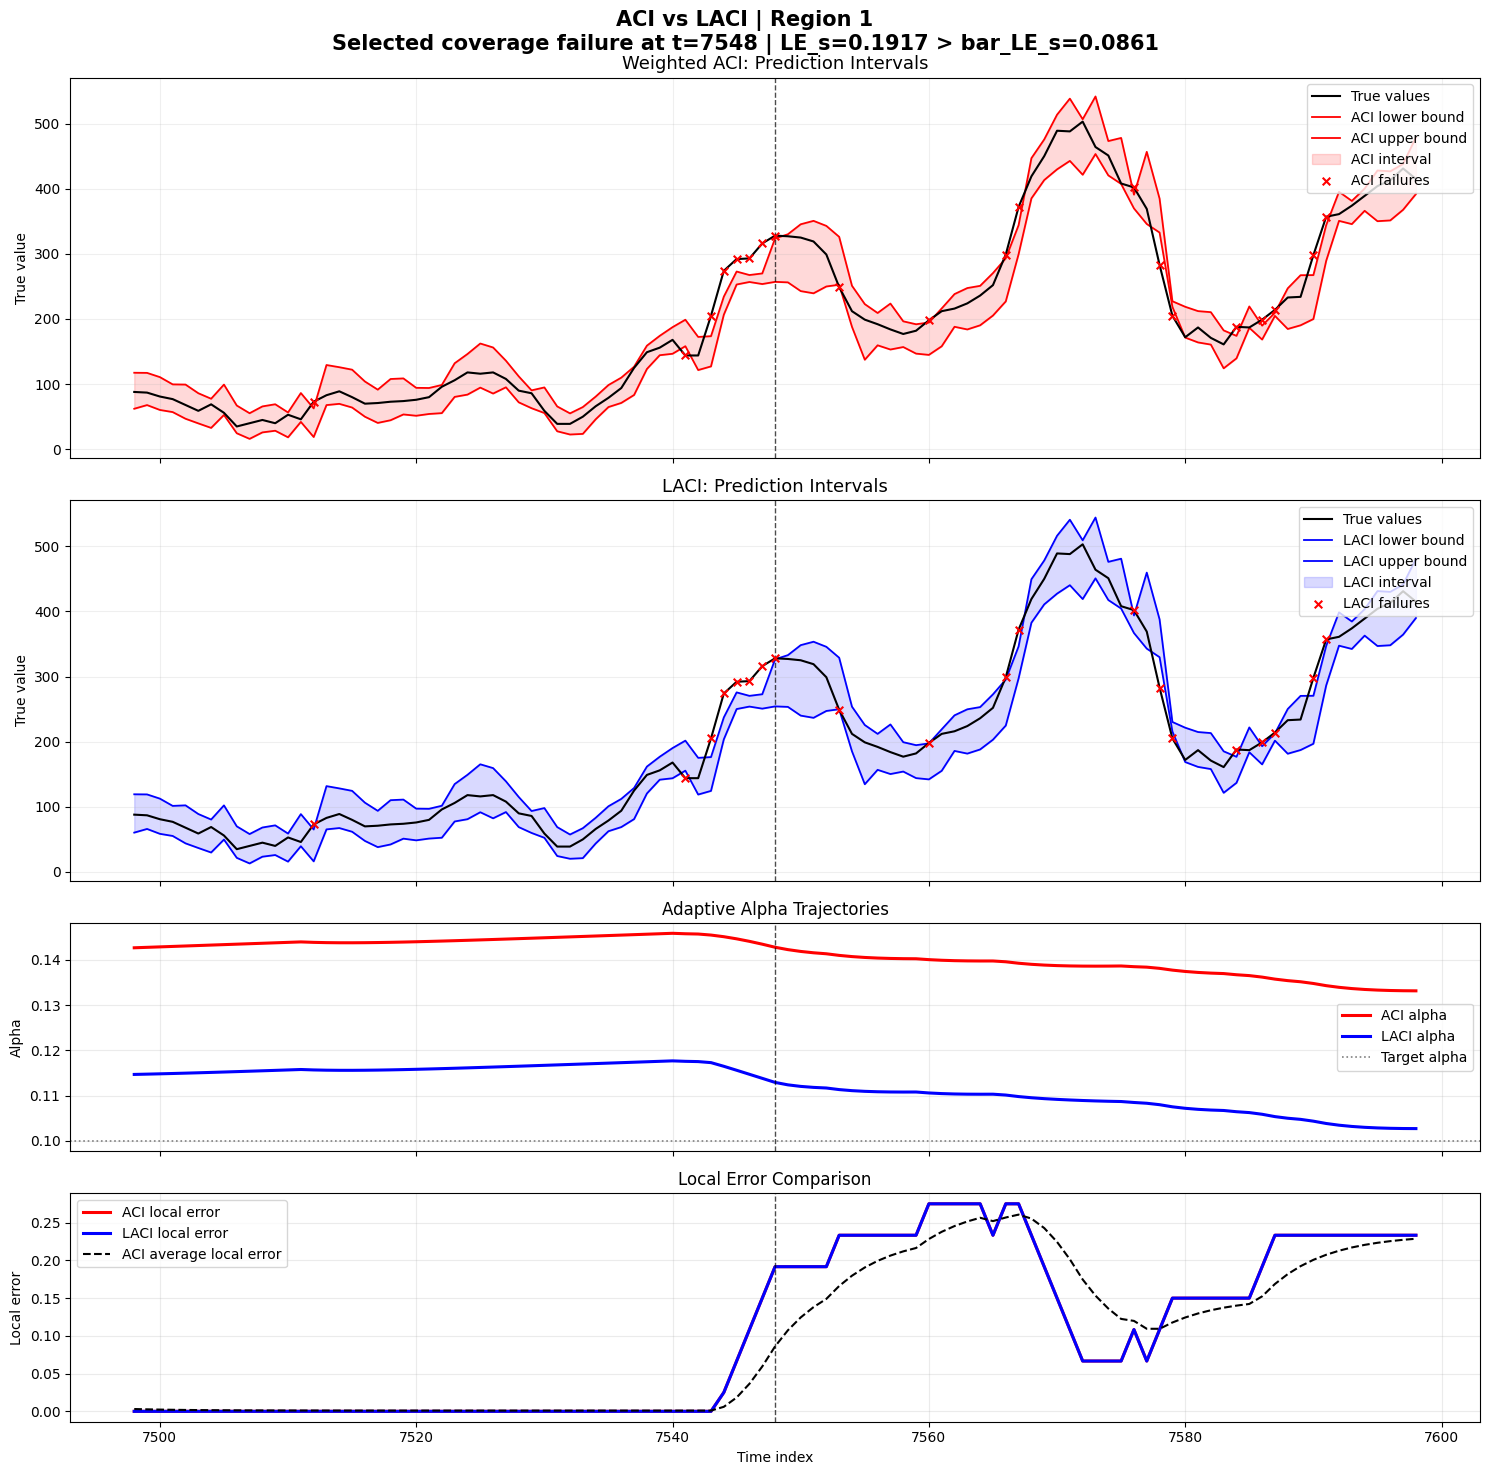

Saved: ./ACI_LACI_alpha_LE_regions\ACI_LACI_Comparison_Region_1_t7548.png


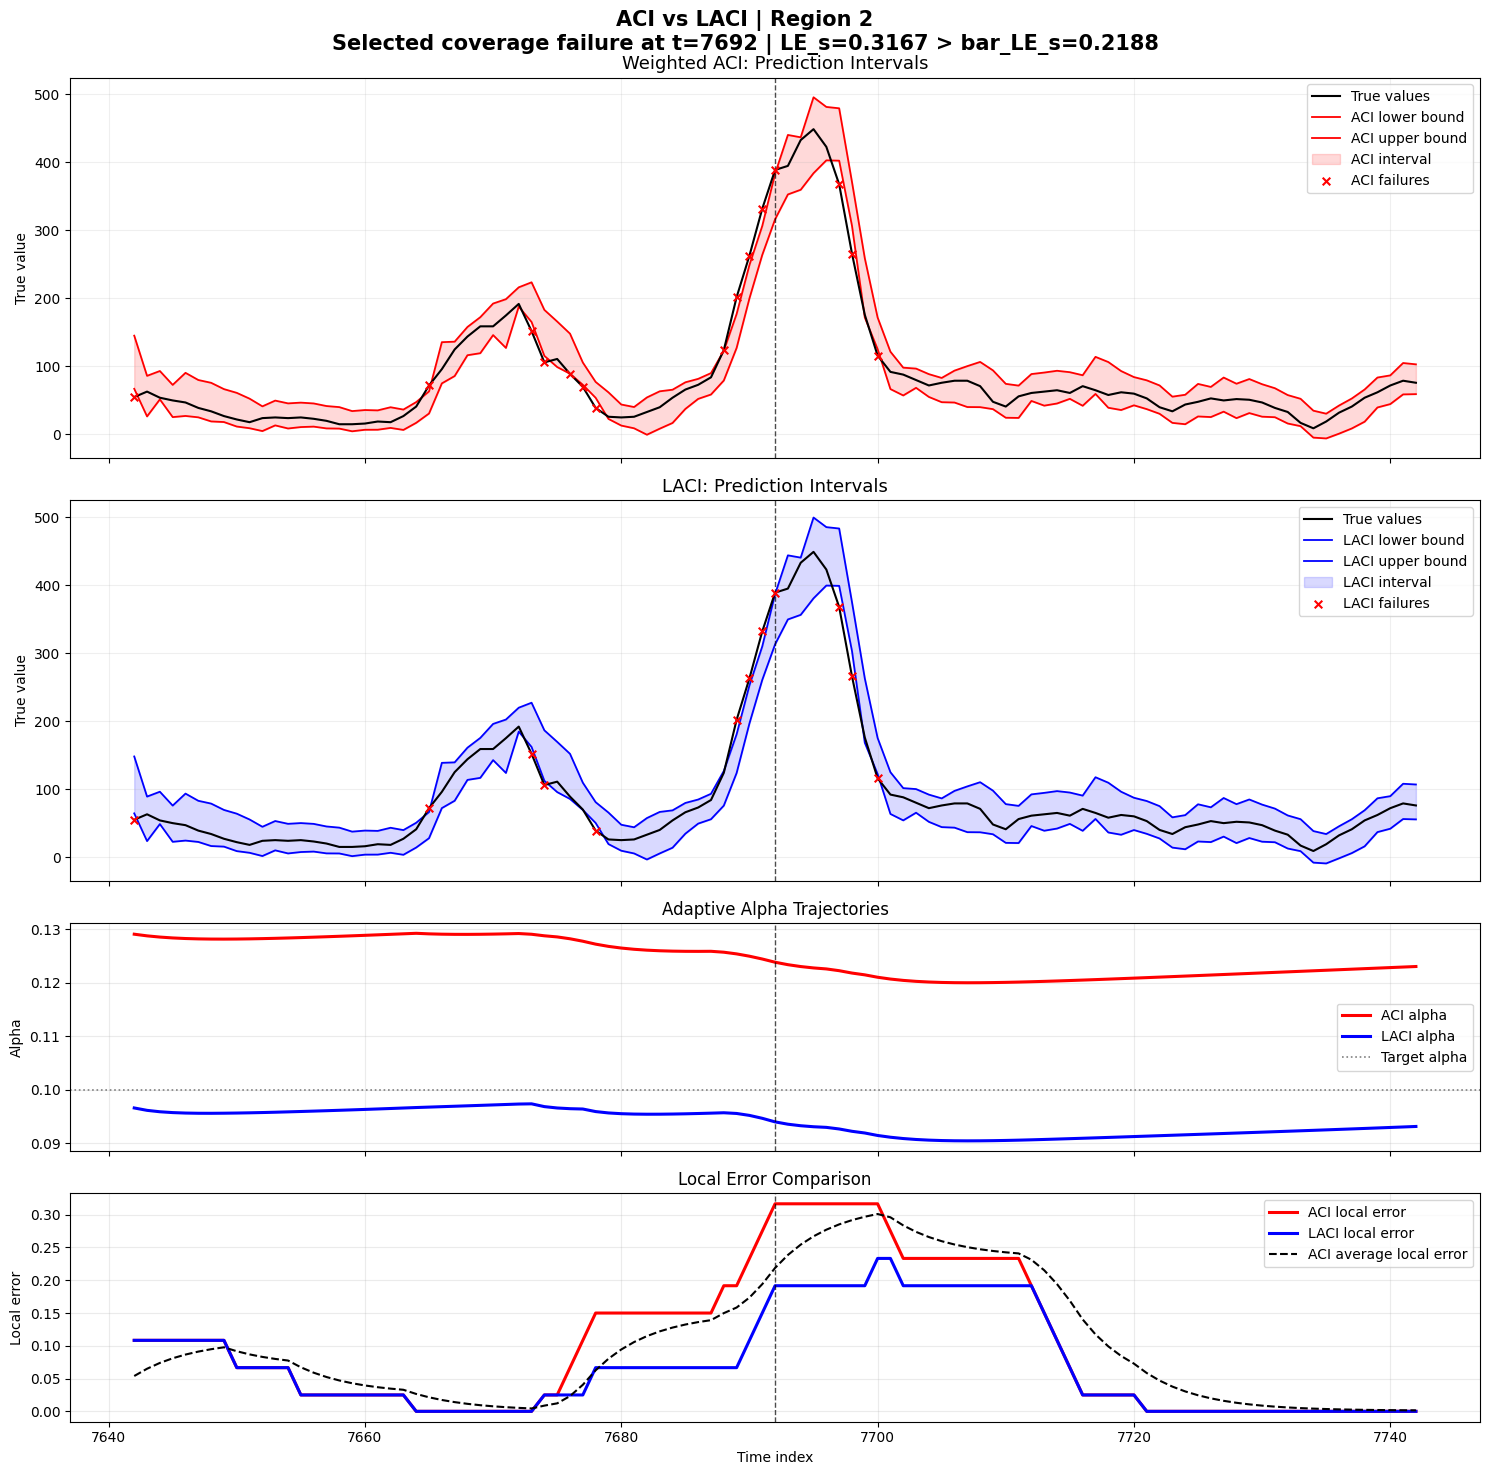

Saved: ./ACI_LACI_alpha_LE_regions\ACI_LACI_Comparison_Region_2_t7692.png


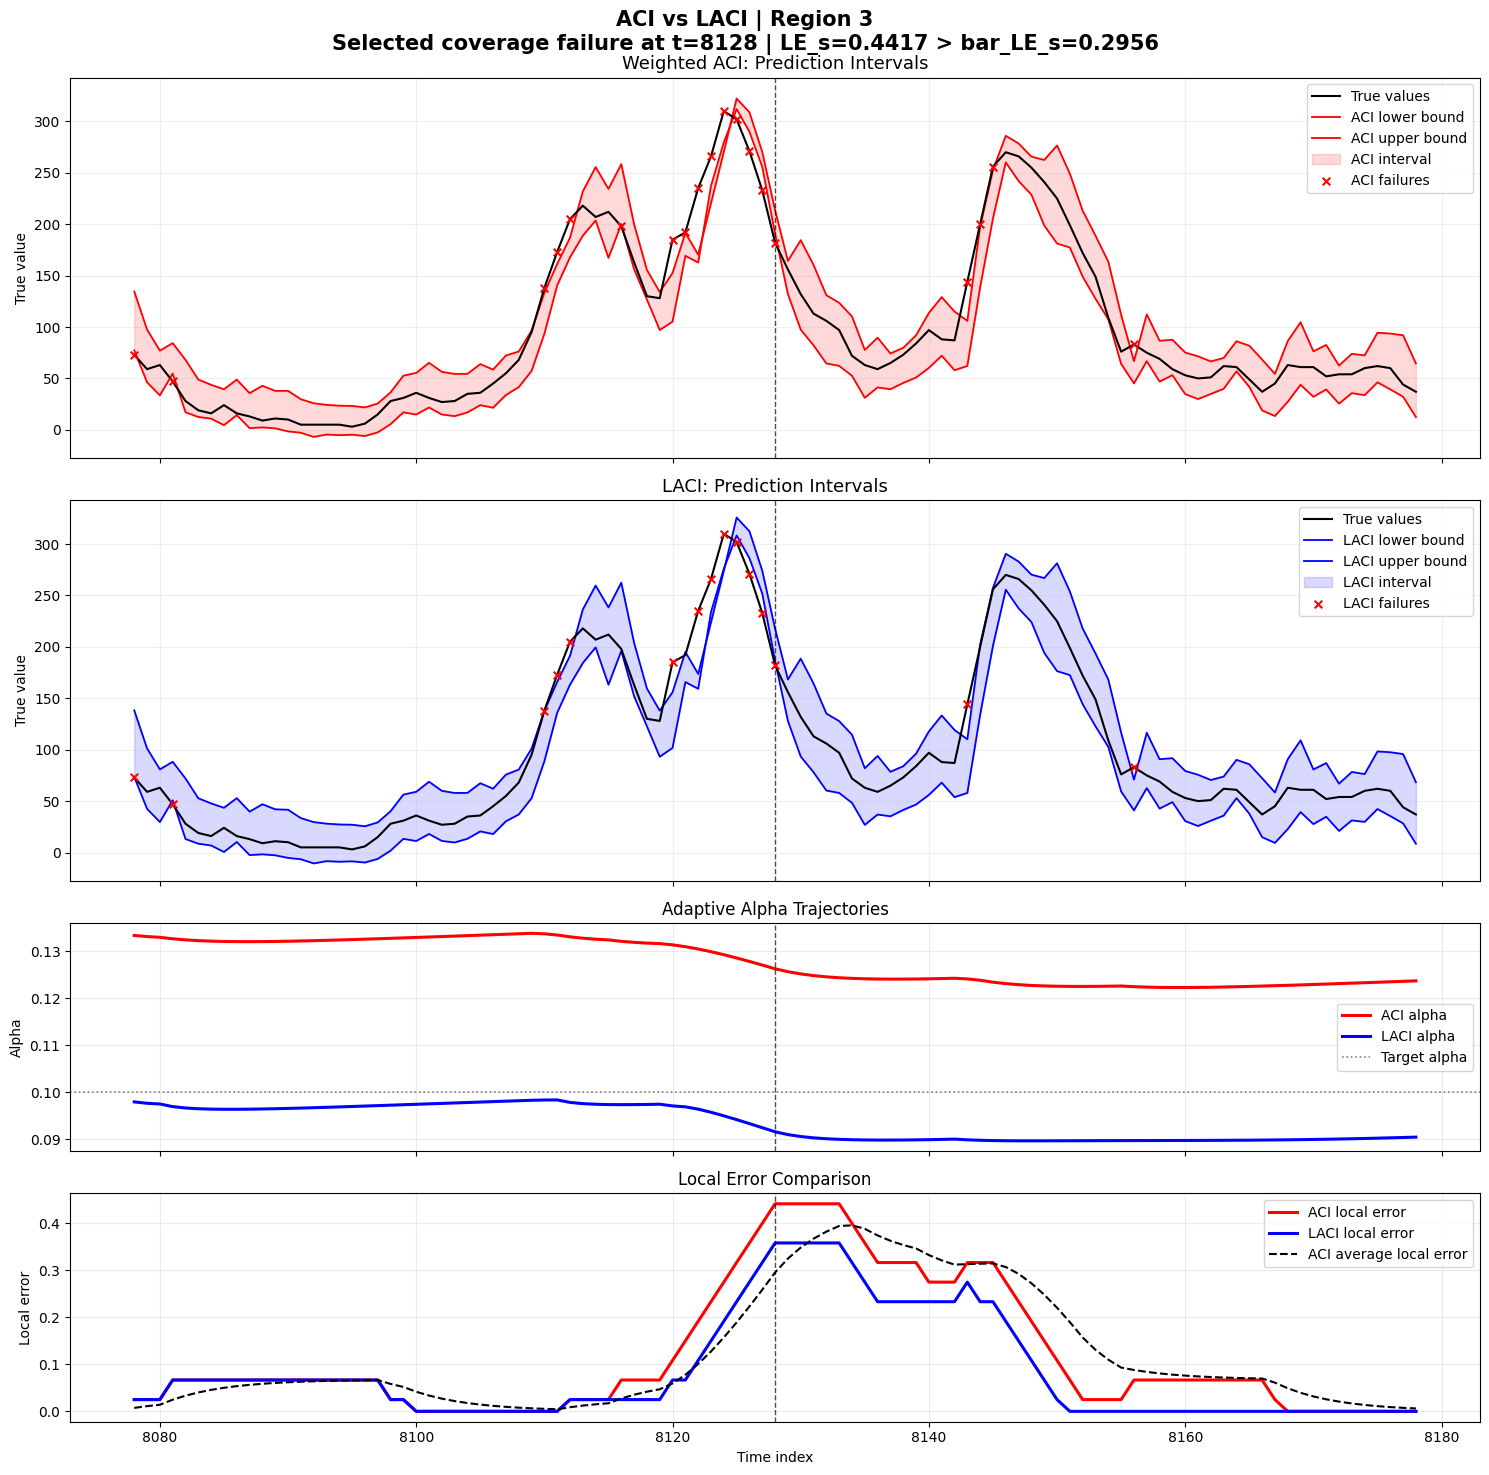

Saved: ./ACI_LACI_alpha_LE_regions\ACI_LACI_Comparison_Region_3_t8128.png


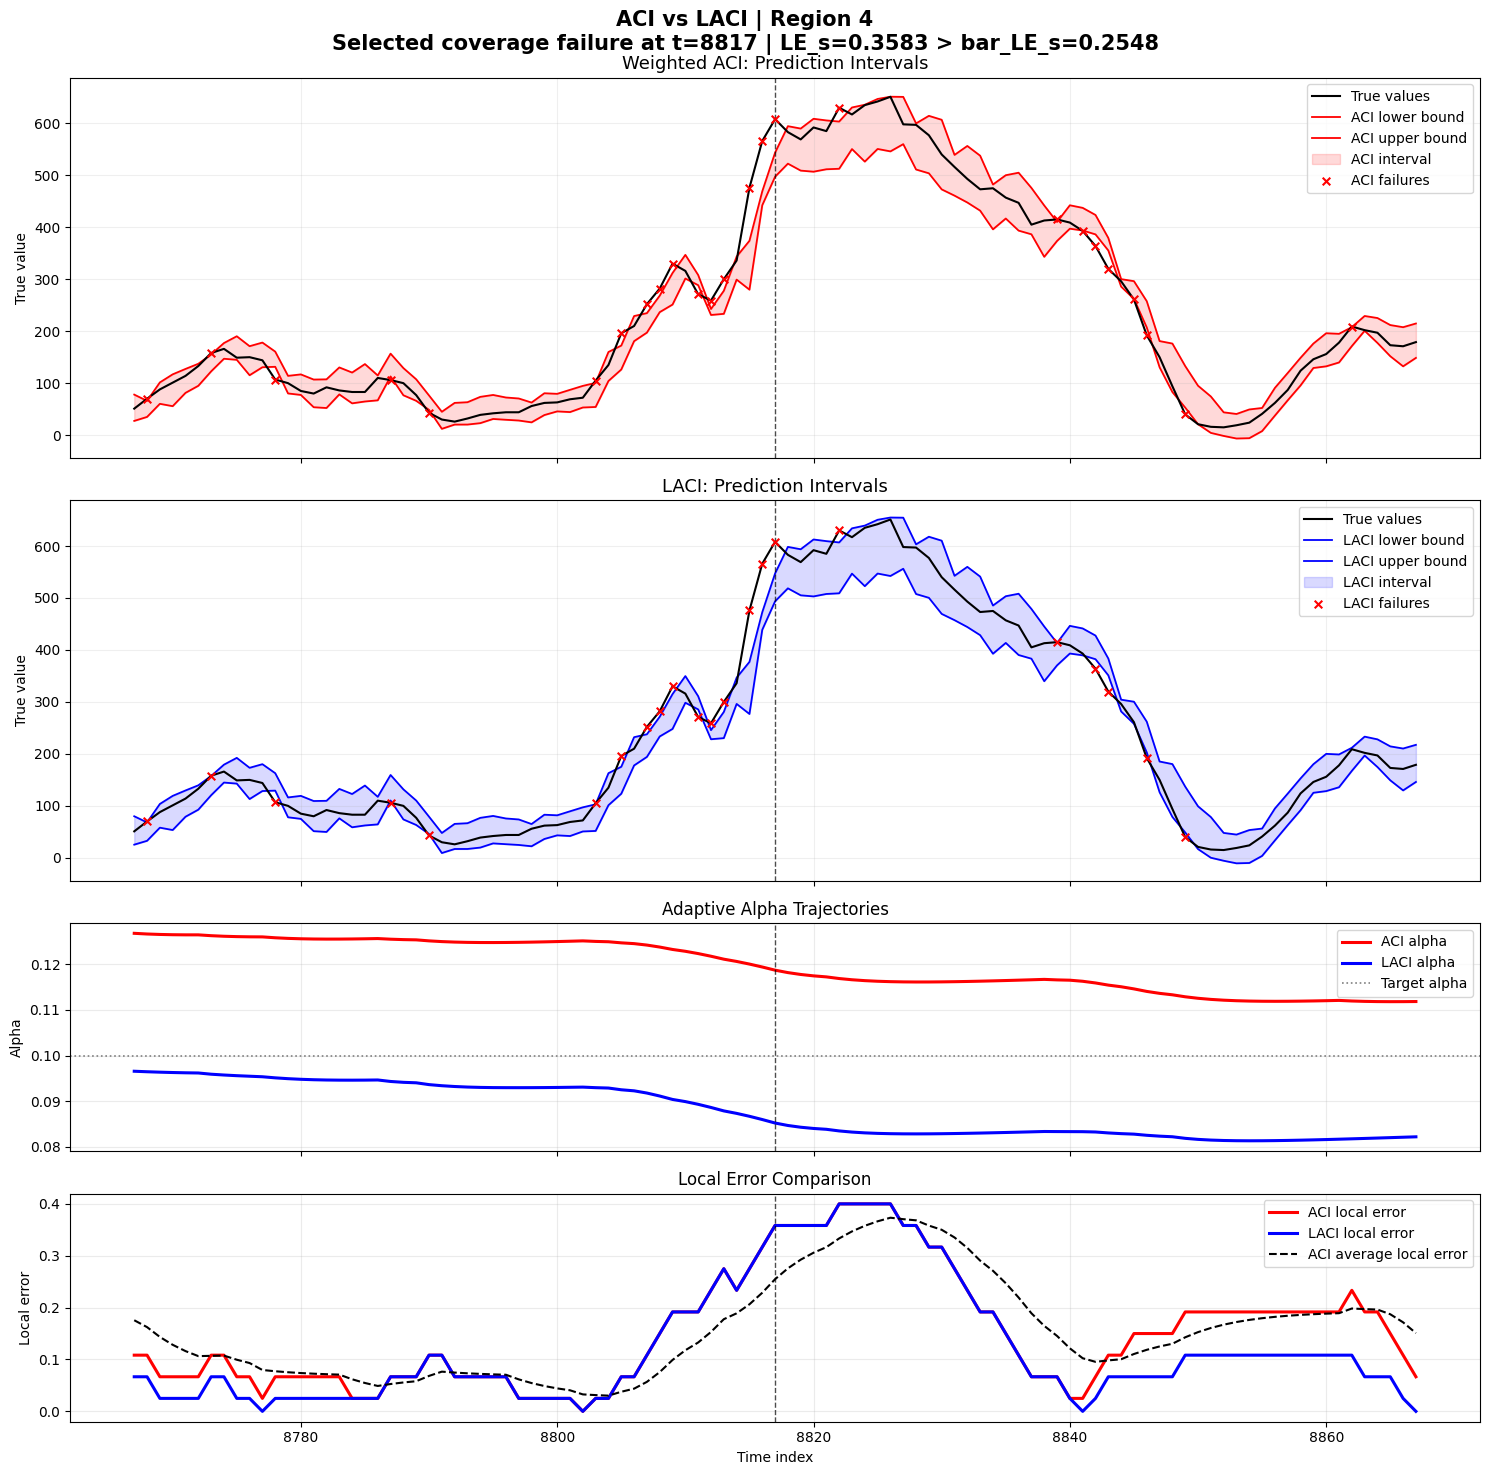

Saved: ./ACI_LACI_alpha_LE_regions\ACI_LACI_Comparison_Region_4_t8817.png


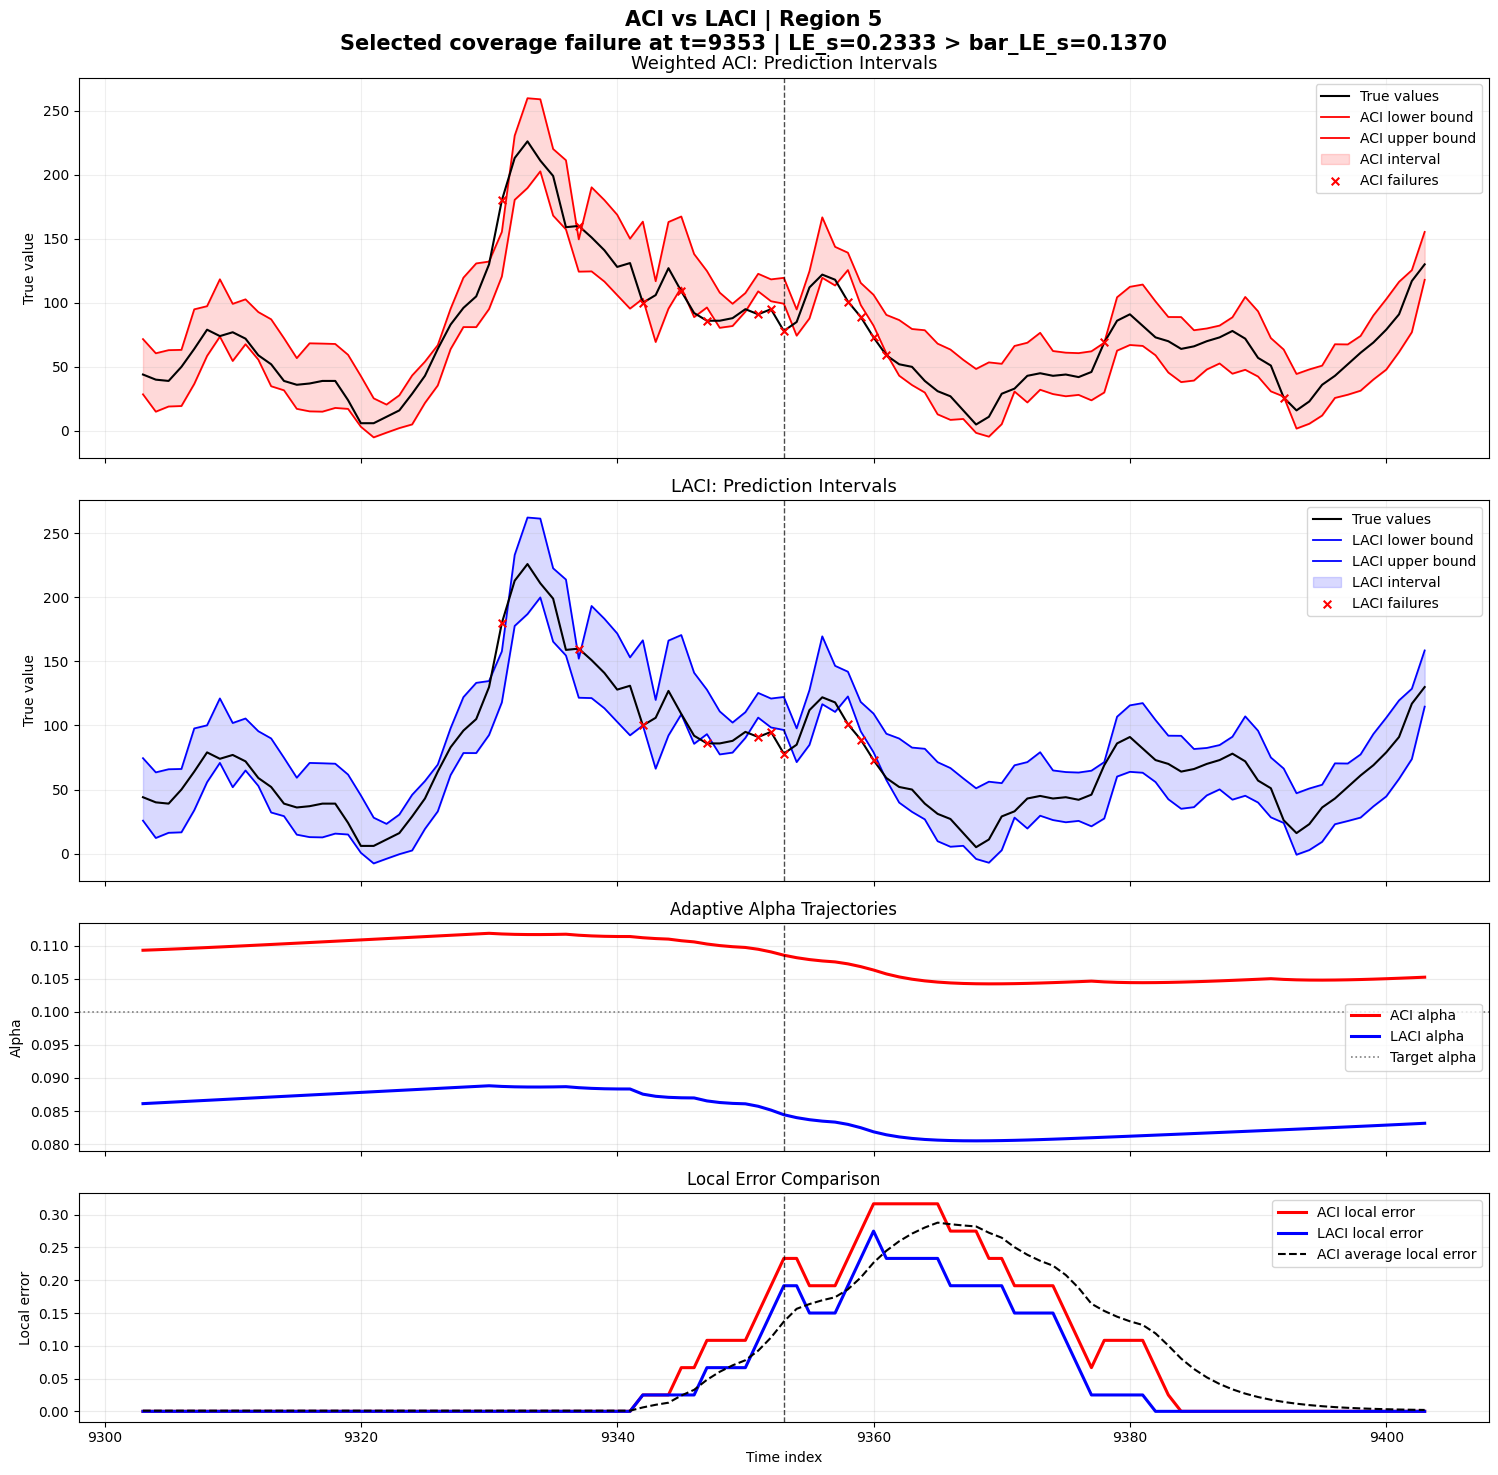

Saved: ./ACI_LACI_alpha_LE_regions\ACI_LACI_Comparison_Region_5_t9353.png


In [9]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ============================================================
# CONFIG
# ============================================================
DATASET_PATHS = [
    "../Datasets/50Hertz.csv",
    "../Datasets/Amprion.csv",
    "../Datasets/TenneTTSO.csv",
    "../Datasets/TransnetBW.csv"

     
]
DATASET_TO_COMPARE = DATASET_PATHS[0]   # change if you want another dataset
N_REGIONS = 5                           # number of points/regions to visualize
CONTEXT_BEFORE = 50
CONTEXT_AFTER = 50
MIN_SEPARATION = 100                    # avoid overlapping selected regions

L = 24                     # local window already used in notebook
EPS = LACI_EPS                          # from your notebook
SAVE_DIR = "./ACI_LACI_alpha_LE_regions"
os.makedirs(SAVE_DIR, exist_ok=True)

# ============================================================
# HELPERS
# ============================================================

def reset_all_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def run_reproducibly(run_fn, full_dataset):
    reset_all_seeds(SEED)
    return run_fn(
        full_dataset,
        alpha=ALPHA,
        gamma=GAMMA,
        decay=DECAY,
        tinit=TINIT,
        splitSize=SPLIT
    )

def prepare_result(result, scaler):
    alpha_t, errors, upper, lower, y_true = result
    return {
        "alpha": np.asarray(alpha_t, dtype=float),
        "errors": np.asarray(errors, dtype=float),
        "upper": scaler.inverse_transform(np.asarray(upper).reshape(-1, 1)).ravel(),
        "lower": scaler.inverse_transform(np.asarray(lower).reshape(-1, 1)).ravel(),
        "y": scaler.inverse_transform(np.asarray(y_true).reshape(-1, 1)).ravel(),
    }

def rolling_lpicp_and_le(errors, alpha, window):
    """
    errors[t] = 1 if miscoverage, 0 if covered
    LPICP_s(L) = local empirical coverage over last L points
    LE_s(L) = max((1-alpha) - LPICP_s(L), 0)
            = max(local miscoverage - alpha, 0)
    """
    err_mean = pd.Series(errors).rolling(window=window, min_periods=window).mean().to_numpy()
    lpicp = 1.0 - err_mean
    le = np.maximum((1.0 - alpha) - lpicp, 0.0)
    return lpicp, le

def normalization_ratio_bar_le(le_values, decay, eps):
    """
    bar_LE_s(L) = Z_LACI_s / Z_ACI_s
    where
      Z_ACI_s  = sum delta^(...) * 1
      Z_LACI_s = sum delta^(...) * (LE + eps)
    implemented recursively.
    """
    z_aci = 0.0
    z_laci = 0.0
    bar_le = np.full(len(le_values), np.nan)

    for s in range(len(le_values)):
        if np.isfinite(le_values[s]):
            z_aci = decay * z_aci + 1.0
            z_laci = decay * z_laci + (le_values[s] + eps)
            bar_le[s] = z_laci / z_aci

    return bar_le

def select_shift_points(le_aci, bar_le_aci, n_regions, context_before, context_after, min_sep):
    """
    Select points where LE_s > bar_LE_s using ACI trajectory.
    Rank by largest positive gap.
    """
    gap = le_aci - bar_le_aci
    valid = (
    np.isfinite(gap)
    & (gap > 0)
    & (ACI["errors"] == 1)
)

    # keep enough context for plotting
    valid[:max(L, context_before)] = False
    valid[max(0, len(valid) - context_after):] = False

    candidates = np.flatnonzero(valid)
    ranked = candidates[np.argsort(gap[candidates])[::-1]]

    selected = []
    for s in ranked:
        if all(abs(s - prev) >= min_sep for prev in selected):
            selected.append(int(s))
        if len(selected) >= n_regions:
            break

    selected.sort()
    return selected, gap

# ============================================================
# 1. LOAD DATASET AND RUN BOTH METHODS
# ============================================================

full_dataset, scaler, _, _ = load_dataset(DATASET_TO_COMPARE, seq_len=SEQ_LEN)

print("Running Weighted ACI...")
aci_raw = run_reproducibly(run_weighted_aci, full_dataset)

print("Running LACI...")
laci_raw = run_reproducibly(run_laci, full_dataset)

ACI = prepare_result(aci_raw, scaler)
LACI = prepare_result(laci_raw, scaler)

assert len(ACI["errors"]) == len(LACI["errors"])
N = len(ACI["errors"])

# This is the forecasting time index corresponding to alpha/error trajectories
time_index = np.arange(N) + TINIT

# ============================================================
# 2. COMPUTE LPICP, LE, AND bar_LE
# ============================================================

LPICP_aci, LE_aci = rolling_lpicp_and_le(ACI["errors"], ALPHA, L)
LPICP_laci, LE_laci = rolling_lpicp_and_le(LACI["errors"], ALPHA, L)

# IMPORTANT:
# We select points based on the ACI trajectory.
bar_LE_aci = normalization_ratio_bar_le(LE_aci, DECAY, EPS)

# ============================================================
# 3. SELECT POINTS s WHERE LE_s(L) > bar_LE_s(L)
# ============================================================

selected_points, gap = select_shift_points(
    LE_aci, bar_LE_aci,
    n_regions=N_REGIONS,
    context_before=CONTEXT_BEFORE,
    context_after=CONTEXT_AFTER,
    min_sep=MIN_SEPARATION
)

print("\nSelected points where LE_s(L) > bar_LE_s(L) (based on ACI):")
for s in selected_points:
    print(
        f"trajectory_idx={s:5d} | "
        f"time={time_index[s]:5d} | "
        f"LE_s={LE_aci[s]:.6f} | "
        f"bar_LE_s={bar_LE_aci[s]:.6f} | "
        f"gap={gap[s]:.6f}"
    )

if len(selected_points) == 0:
    print("\nNo points found with LE_s(L) > bar_LE_s(L).")
    print("Try reducing MIN_SEPARATION or changing DATASET_TO_COMPARE.")
    
# ============================================================
# 4. SUMMARY TABLE
# ============================================================

summary_rows = []

for s in selected_points:
    left = s - CONTEXT_BEFORE
    right = s + CONTEXT_AFTER + 1

    pre_alpha_aci = ACI["alpha"][s - 1] if s > 0 else ALPHA
    pre_alpha_laci = LACI["alpha"][s - 1] if s > 0 else ALPHA

    summary_rows.append({
        "time": int(time_index[s]),
        "trajectory_idx": int(s),
        "LE_s_ACI": float(LE_aci[s]),
        "bar_LE_s_ACI": float(bar_LE_aci[s]),
        "ACI_alpha_at_s": float(ACI["alpha"][s]),
        "LACI_alpha_at_s": float(LACI["alpha"][s]),
        "ACI_alpha_drop_at_s": float(pre_alpha_aci - ACI["alpha"][s]),
        "LACI_alpha_drop_at_s": float(pre_alpha_laci - LACI["alpha"][s]),
        "ACI_mean_LE_region": float(np.nanmean(LE_aci[left:right])),
        "LACI_mean_LE_region": float(np.nanmean(LE_laci[left:right])),
        "ACI_mean_LPICP_region": float(np.nanmean(LPICP_aci[left:right])),
        "LACI_mean_LPICP_region": float(np.nanmean(LPICP_laci[left:right]))
    })

summary_df = pd.DataFrame(summary_rows)

if len(summary_df) > 0:
    print("\n===== Summary comparison =====")
    print(summary_df.round(6).to_string(index=False))
    summary_df.to_csv(os.path.join(SAVE_DIR, "alpha_LE_region_summary.csv"), index=False)
    print(f"\nSaved summary CSV to: {os.path.join(SAVE_DIR, 'alpha_LE_region_summary.csv')}")

# ============================================================
# 5. PLOT ALPHA AND LOCAL ERROR AROUND EACH SELECTED POINT
# ============================================================


# ============================================================
# 5. PLOT FOUR PANELS FOR EACH SELECTED REGION
# ============================================================

for ridx, s in enumerate(selected_points, start=1):

    left = s - CONTEXT_BEFORE
    right = s + CONTEXT_AFTER + 1

    xx = time_index[left:right]
    yy = ACI["y"][left:right]

    fig, axes = plt.subplots(
        4, 1,
        figsize=(15, 15),
        sharex=True,
        gridspec_kw={
            "height_ratios": [2, 2, 1.2, 1.2]
        }
    )

    # ========================================================
    # PANEL 1: ACI PREDICTION INTERVAL
    # ========================================================

    ax = axes[0]

    ax.plot(
        xx, yy,
        color="black",
        linewidth=1.5,
        label="True values",
        zorder=3
    )

    ax.plot(
        xx, ACI["lower"][left:right],
        color="red",
        linewidth=1.3,
        label="ACI lower bound"
    )

    ax.plot(
        xx, ACI["upper"][left:right],
        color="red",
        linewidth=1.3,
        label="ACI upper bound"
    )

    ax.fill_between(
        xx,
        ACI["lower"][left:right],
        ACI["upper"][left:right],
        color="red",
        alpha=0.15,
        label="ACI interval"
    )

    # Highlight ACI coverage failures
    aci_fail = ACI["errors"][left:right] == 1

    ax.scatter(
        xx[aci_fail],
        yy[aci_fail],
        color="red",
        marker="x",
        s=30,
        zorder=5,
        label="ACI failures"
    )

    ax.set_title(
        "Weighted ACI: Prediction Intervals",
        fontsize=13
    )

    ax.set_ylabel("True value")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.2)

    # ========================================================
    # PANEL 2: LACI PREDICTION INTERVAL
    # ========================================================

    ax = axes[1]

    ax.plot(
        xx, yy,
        color="black",
        linewidth=1.5,
        label="True values",
        zorder=3
    )

    ax.plot(
        xx, LACI["lower"][left:right],
        color="blue",
        linewidth=1.3,
        label="LACI lower bound"
    )

    ax.plot(
        xx, LACI["upper"][left:right],
        color="blue",
        linewidth=1.3,
        label="LACI upper bound"
    )

    ax.fill_between(
        xx,
        LACI["lower"][left:right],
        LACI["upper"][left:right],
        color="blue",
        alpha=0.15,
        label="LACI interval"
    )

    # Highlight LACI coverage failures
    laci_fail = LACI["errors"][left:right] == 1

    ax.scatter(
        xx[laci_fail],
        yy[laci_fail],
        color="red",
        marker="x",
        s=30,
        zorder=5,
        label="LACI failures"
    )

    ax.set_title(
        "LACI: Prediction Intervals",
        fontsize=13
    )

    ax.set_ylabel("True value")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.2)

    # Equal y-axis scaling for fair comparison
    all_y = np.concatenate([
        yy,
        ACI["lower"][left:right],
        ACI["upper"][left:right],
        LACI["lower"][left:right],
        LACI["upper"][left:right]
    ])

    y_min = np.nanmin(all_y)
    y_max = np.nanmax(all_y)
    padding = max(0.05 * (y_max - y_min), 1e-6)

    axes[0].set_ylim(y_min-padding, y_max+padding)
    axes[1].set_ylim(y_min-padding, y_max+padding)

    # ========================================================
    # PANEL 3: ALPHA TRAJECTORY
    # ========================================================

    ax = axes[2]

    ax.plot(
        xx,
        ACI["alpha"][left:right],
        color="red",
        linewidth=2.2,
        label="ACI alpha"
    )

    ax.plot(
        xx,
        LACI["alpha"][left:right],
        color="blue",
        linewidth=2.2,
        label="LACI alpha"
    )

    ax.axhline(
        ALPHA,
        color="gray",
        linestyle=":",
        linewidth=1.2,
        label="Target alpha"
    )

    ax.set_title("Adaptive Alpha Trajectories")
    ax.set_ylabel("Alpha")
    ax.legend(loc="best")
    ax.grid(alpha=0.25)

    # ========================================================
    # PANEL 4: LOCAL ERROR TRAJECTORY
    # ========================================================

    ax = axes[3]

    ax.plot(
        xx,
        LE_aci[left:right],
        color="red",
        linewidth=2.2,
        label="ACI local error"
    )

    ax.plot(
        xx,
        LE_laci[left:right],
        color="blue",
        linewidth=2.2,
        label="LACI local error"
    )

    ax.plot(
        xx,
        bar_LE_aci[left:right],
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="ACI average local error"
    )

    ax.set_title("Local Error Comparison")
    ax.set_ylabel("Local error")
    ax.set_xlabel("Time index")
    ax.legend(loc="best")
    ax.grid(alpha=0.25)

    # ========================================================
    # SELECTED POINT MARKER
    # ========================================================

    for ax in axes:
        ax.axvline(
            time_index[s],
            color="black",
            linestyle="--",
            linewidth=1,
            alpha=0.7
        )

    # ========================================================
    # TITLE AND SAVE
    # ========================================================

    fig.suptitle(
        f"ACI vs LACI | Region {ridx}\n"
        f"Selected coverage failure at t={time_index[s]} | "
        f"LE_s={LE_aci[s]:.4f} > "
        f"bar_LE_s={bar_LE_aci[s]:.4f}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()

    save_path = os.path.join(
        SAVE_DIR,
        f"ACI_LACI_Comparison_Region_{ridx}_t{time_index[s]}.png"
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"Saved: {save_path}")


Generated observations: 5000
   start   end      type  magnitude
0   2300  2432  variance   4.951245
1   3000  3216      mean   5.358193
2   3350  3537  variance   3.900772
3   3700  3836      mean   5.780295
4   4400  4568  variance   4.287730


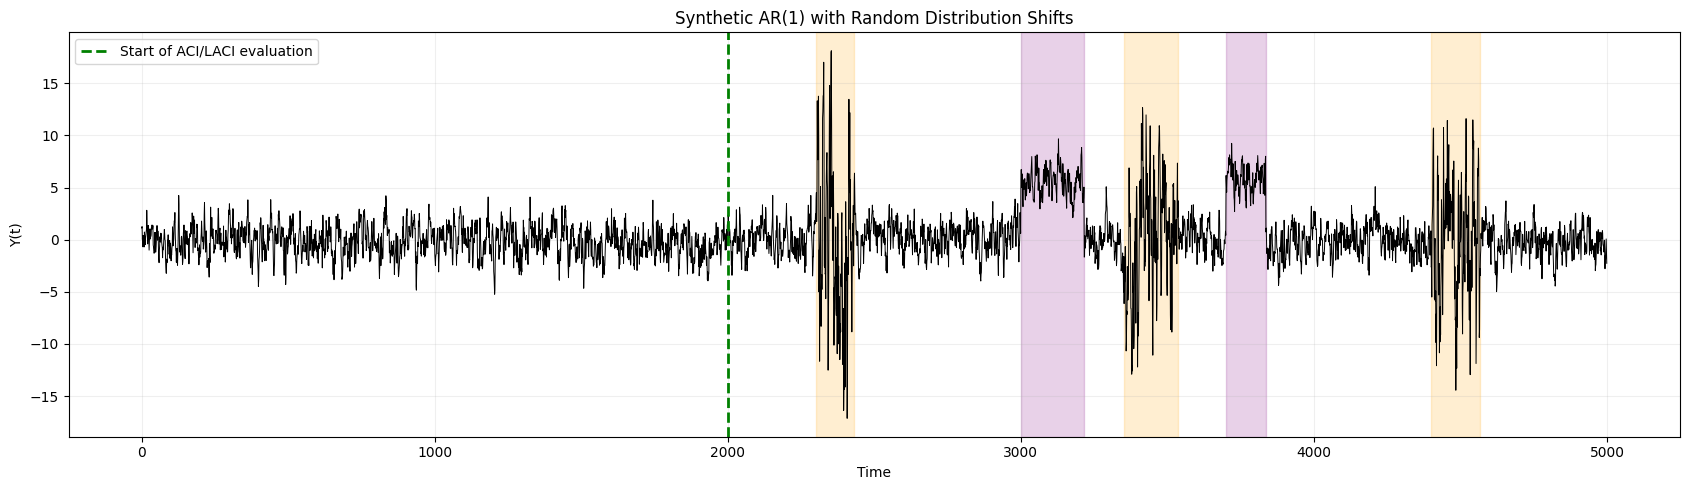

In [1]:
#With AR process 


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# SYNTHETIC AR(1) WITH RANDOM DISTRIBUTION SHIFTS
# ============================================================

SEED = 42
rng = np.random.default_rng(SEED)

T = 5000
PHI = 0.7

mu = np.zeros(T)
sigma = np.ones(T)

# Randomly select shifts inside the evaluation portion.
# These are separated so individual shift effects can be studied.
shift_candidates = np.arange(2300, 4600, 350)
shift_points = np.sort(
    rng.choice(shift_candidates, size=5, replace=False)
)

shift_records = []

for i, start in enumerate(shift_points):

    duration = int(rng.integers(120, 251))
    end = min(start + duration, T)

    if i % 2 == 0:
        # Variance shift
        magnitude = float(rng.uniform(3.0, 5.0))
        sigma[start:end] = magnitude
        shift_type = "variance"

    else:
        # Mean shift
        magnitude = float(
            rng.choice([-1, 1]) * rng.uniform(3.0, 6.0)
        )
        mu[start:end] = magnitude
        shift_type = "mean"

    shift_records.append({
        "start": int(start),
        "end": int(end),
        "type": shift_type,
        "magnitude": magnitude
    })

# Generate AR(1) observations
y = np.zeros(T)
y[0] = rng.normal(mu[0], sigma[0])

for t in range(1, T):
    y[t] = (
        mu[t]
        + PHI * (y[t-1] - mu[t-1])
        + sigma[t] * rng.normal()
    )

df = pd.DataFrame({
    "time": np.arange(T),
    "Power": y,
    "mu": mu,
    "sigma": sigma
})

df.to_csv("synthetic_AR1_shifts.csv", index=False)

print("Generated observations:", len(df))
print(pd.DataFrame(shift_records))

# ============================================================
# VISUALIZE THE FULL SERIES
# ============================================================

plt.figure(figsize=(17, 5))

plt.plot(
    df["time"], df["Power"],
    color="black", linewidth=0.7
)

for shift in shift_records:
    color = (
        "orange" if shift["type"] == "variance"
        else "purple"
    )

    plt.axvspan(
        shift["start"],
        shift["end"],
        color=color,
        alpha=0.18
    )

plt.axvline(
    2000,
    color="green",
    linestyle="--",
    linewidth=2,
    label="Start of ACI/LACI evaluation"
)

plt.title("Synthetic AR(1) with Random Distribution Shifts")
plt.xlabel("Time")
plt.ylabel("Y(t)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [4]:

import torch
import random
from sklearn.preprocessing import StandardScaler

# ============================================================
# PREPARE DATA
# ============================================================

SEQ_LEN = 48
SYNTHETIC_TINIT = T - SEQ_LEN - 3000

assert SYNTHETIC_TINIT > 0

# Scale using only the initial history to avoid future leakage
scaler = StandardScaler()
scaler.fit(y[:2000].reshape(-1, 1))

y_scaled = scaler.transform(
    y.reshape(-1, 1)
).flatten().astype(np.float32)

full_dataset = SeqDataset(y_scaled, SEQ_LEN)

assert len(full_dataset) - SYNTHETIC_TINIT == 3000

# ============================================================
# RUN BOTH METHODS
# ============================================================

def run_synthetic(fn):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    return fn(
        full_dataset,
        alpha=ALPHA,
        gamma=GAMMA,
        decay=DECAY,
        tinit=SYNTHETIC_TINIT,
        splitSize=SPLIT
    )

print("Running Weighted ACI...")
aci_raw = run_synthetic(run_weighted_aci)

print("Running LACI...")
laci_raw = run_synthetic(run_laci)

print("ACI observations:", len(aci_raw[0]))
print("LACI observations:", len(laci_raw[0]))


Running Weighted ACI...
[Weighted_ACI] t=2000, alphat=0.0999, weighted_err=0.0340
[Weighted_ACI] t=2200, alphat=0.1066, weighted_err=0.1939
[Weighted_ACI] t=2400, alphat=0.0398, weighted_err=0.0011
[Weighted_ACI] t=2600, alphat=0.0598, weighted_err=0.0000
[Weighted_ACI] t=2800, alphat=0.0798, weighted_err=0.0000
[Weighted_ACI] t=3000, alphat=0.0791, weighted_err=0.0776
[Weighted_ACI] t=3200, alphat=0.0768, weighted_err=0.0001
[Weighted_ACI] t=3400, alphat=0.0633, weighted_err=0.1148
[Weighted_ACI] t=3600, alphat=0.0648, weighted_err=0.0000
[Weighted_ACI] t=3800, alphat=0.0778, weighted_err=0.0088
[Weighted_ACI] t=4000, alphat=0.0968, weighted_err=0.0000
[Weighted_ACI] t=4200, alphat=0.1118, weighted_err=0.0000
[Weighted_ACI] t=4400, alphat=0.1091, weighted_err=0.0638
[Weighted_ACI] t=4600, alphat=0.0924, weighted_err=0.1610
[Weighted_ACI] t=4800, alphat=0.1038, weighted_err=0.0002
Running LACI...
[LACI] t=2000, alphat=0.0989, weighted_err=0.0169
[LACI] t=2200, alphat=0.1026, weighted_e

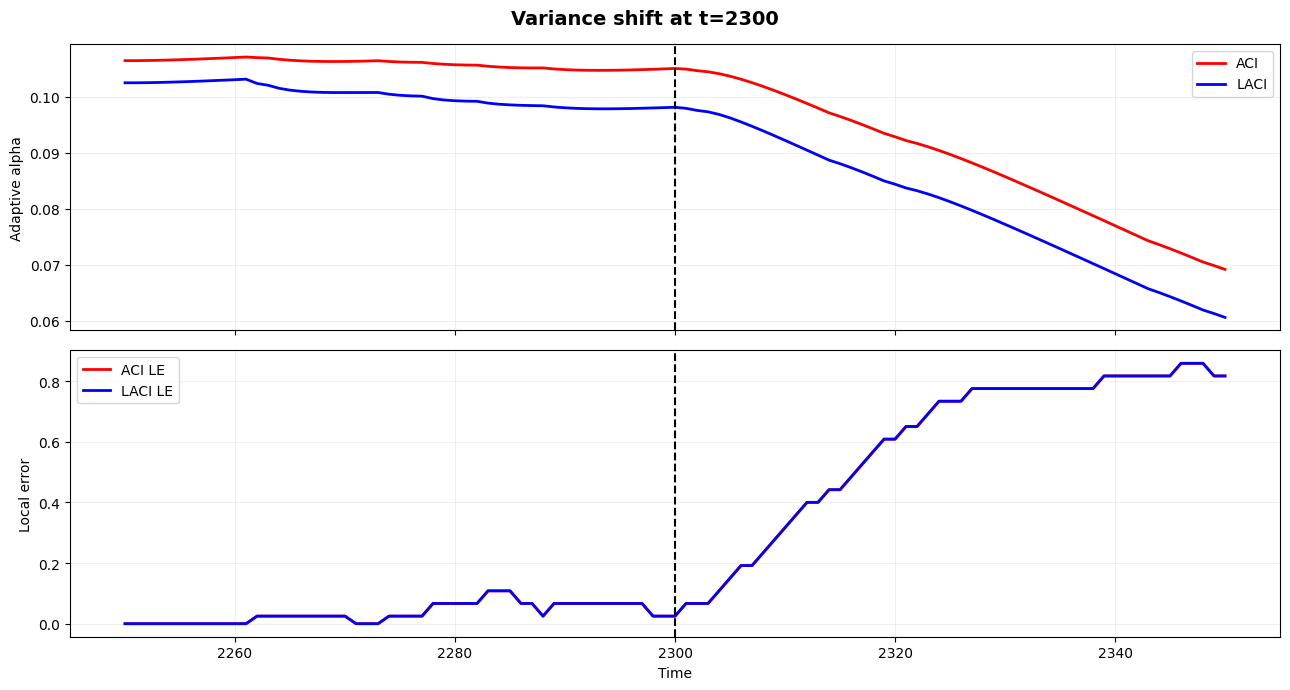

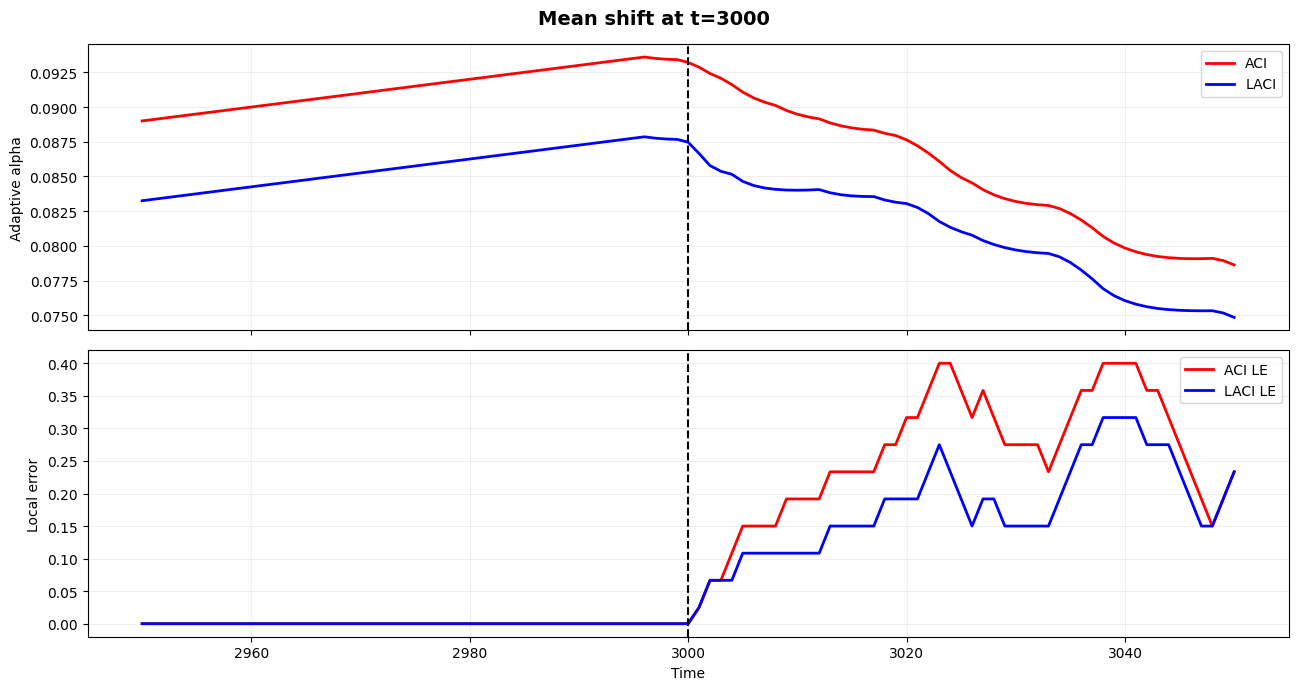

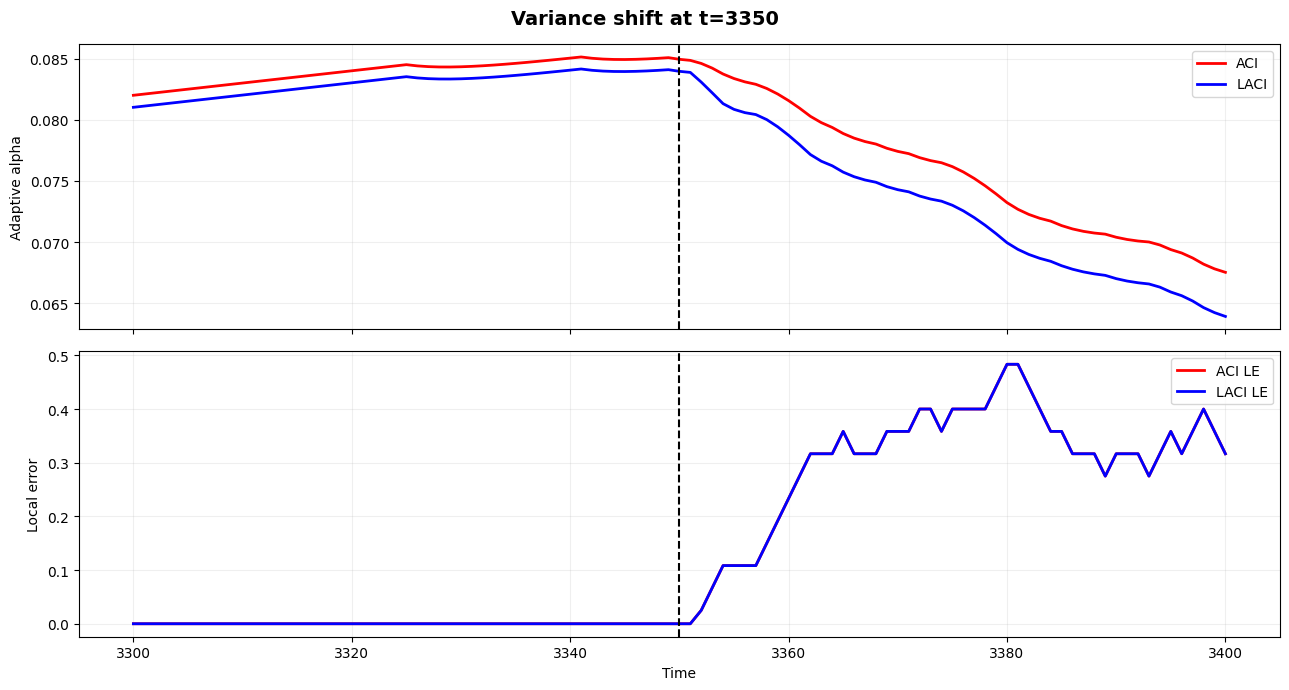

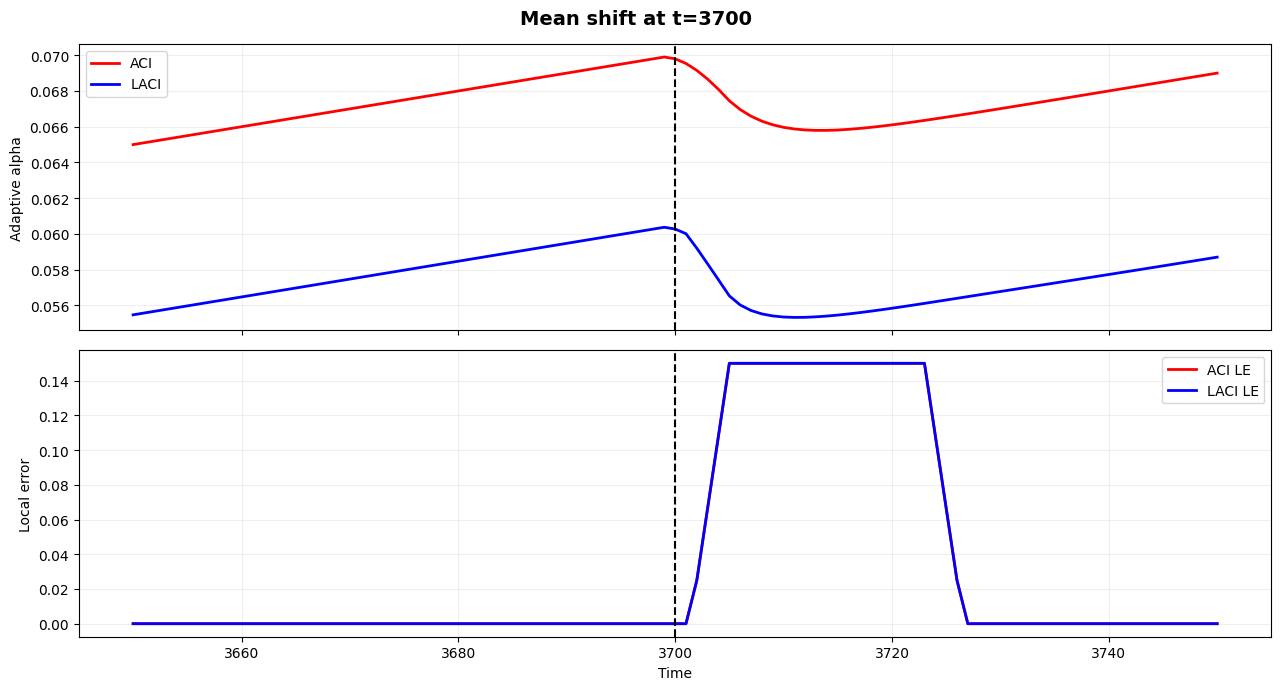

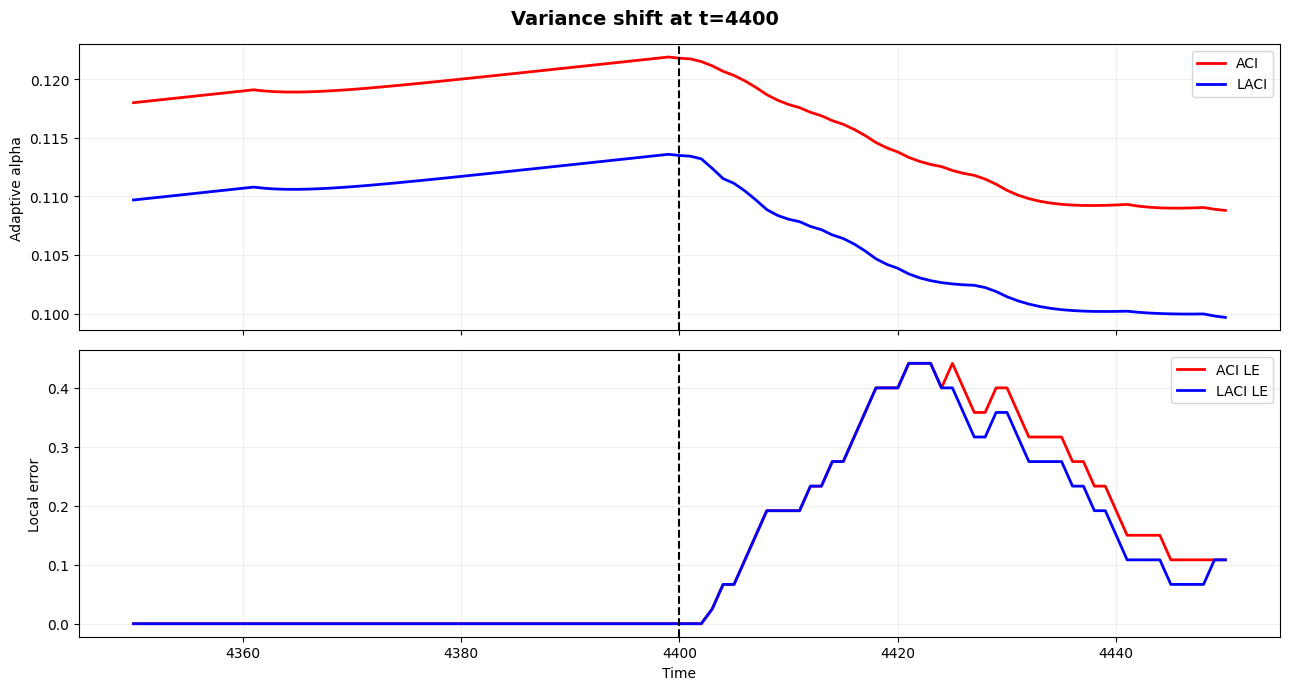

In [5]:

def unpack(result):
    alpha_traj, errors, upper, lower, actual = result
    return {
        "alpha": np.asarray(alpha_traj),
        "errors": np.asarray(errors),
        "upper": np.asarray(upper),
        "lower": np.asarray(lower),
        "actual": np.asarray(actual)
    }

ACI = unpack(aci_raw)
LACI = unpack(laci_raw)

def compute_LE(errors, window, alpha):
    local_miscoverage = pd.Series(errors).rolling(
        window=window,
        min_periods=window
    ).mean().to_numpy()

    return np.maximum(local_miscoverage - alpha, 0)

LE_aci = compute_LE(ACI["errors"], LOCAL_WINDOW, ALPHA)
LE_laci = compute_LE(LACI["errors"], LOCAL_WINDOW, ALPHA)

# Actual indices in the original 5000-point series
time = np.arange(2000, 5000)

for shift in shift_records:

    s = shift["start"]

    mask = (time >= s - 50) & (time <= s + 50)
    xx = time[mask]

    fig, axes = plt.subplots(
        2, 1, figsize=(13, 7), sharex=True
    )

    axes[0].plot(
        xx, ACI["alpha"][mask],
        color="red", label="ACI", linewidth=2
    )

    axes[0].plot(
        xx, LACI["alpha"][mask],
        color="blue", label="LACI", linewidth=2
    )

    axes[0].axvline(s, color="black", linestyle="--")
    axes[0].set_ylabel("Adaptive alpha")
    axes[0].legend()
    axes[0].grid(alpha=0.2)

    axes[1].plot(
        xx, LE_aci[mask],
        color="red", label="ACI LE", linewidth=2
    )

    axes[1].plot(
        xx, LE_laci[mask],
        color="blue", label="LACI LE", linewidth=2
    )

    axes[1].axvline(s, color="black", linestyle="--")
    axes[1].set_ylabel("Local error")
    axes[1].set_xlabel("Time")
    axes[1].legend()
    axes[1].grid(alpha=0.2)

    fig.suptitle(
        f"{shift['type'].capitalize()} shift at t={s}",
        fontsize=14, fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


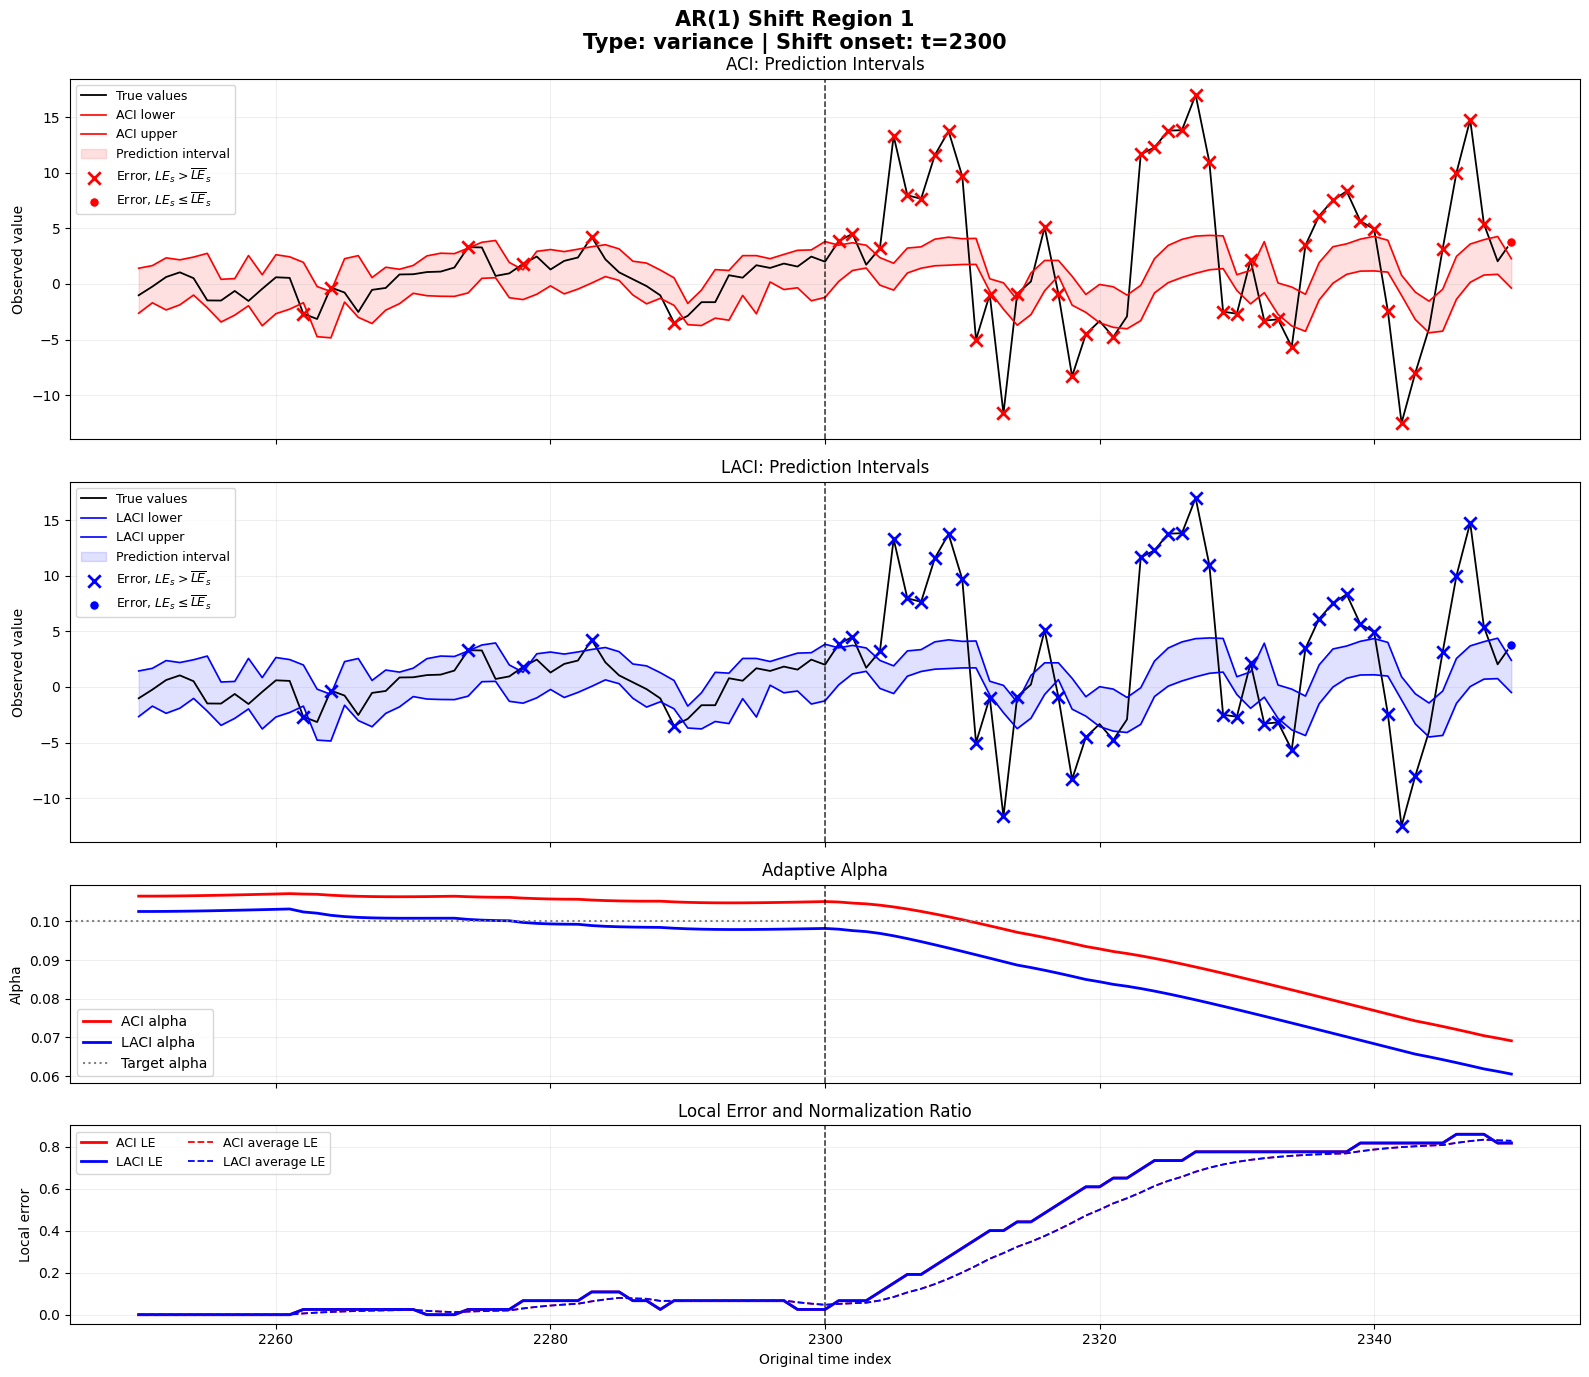


Region 1 (t=2300):
ACI: 49 crosses, 1 dots
LACI: 49 crosses, 1 dots
Saved: ./synthetic_AR1_shift_plots\shift_region_1_t2300.png


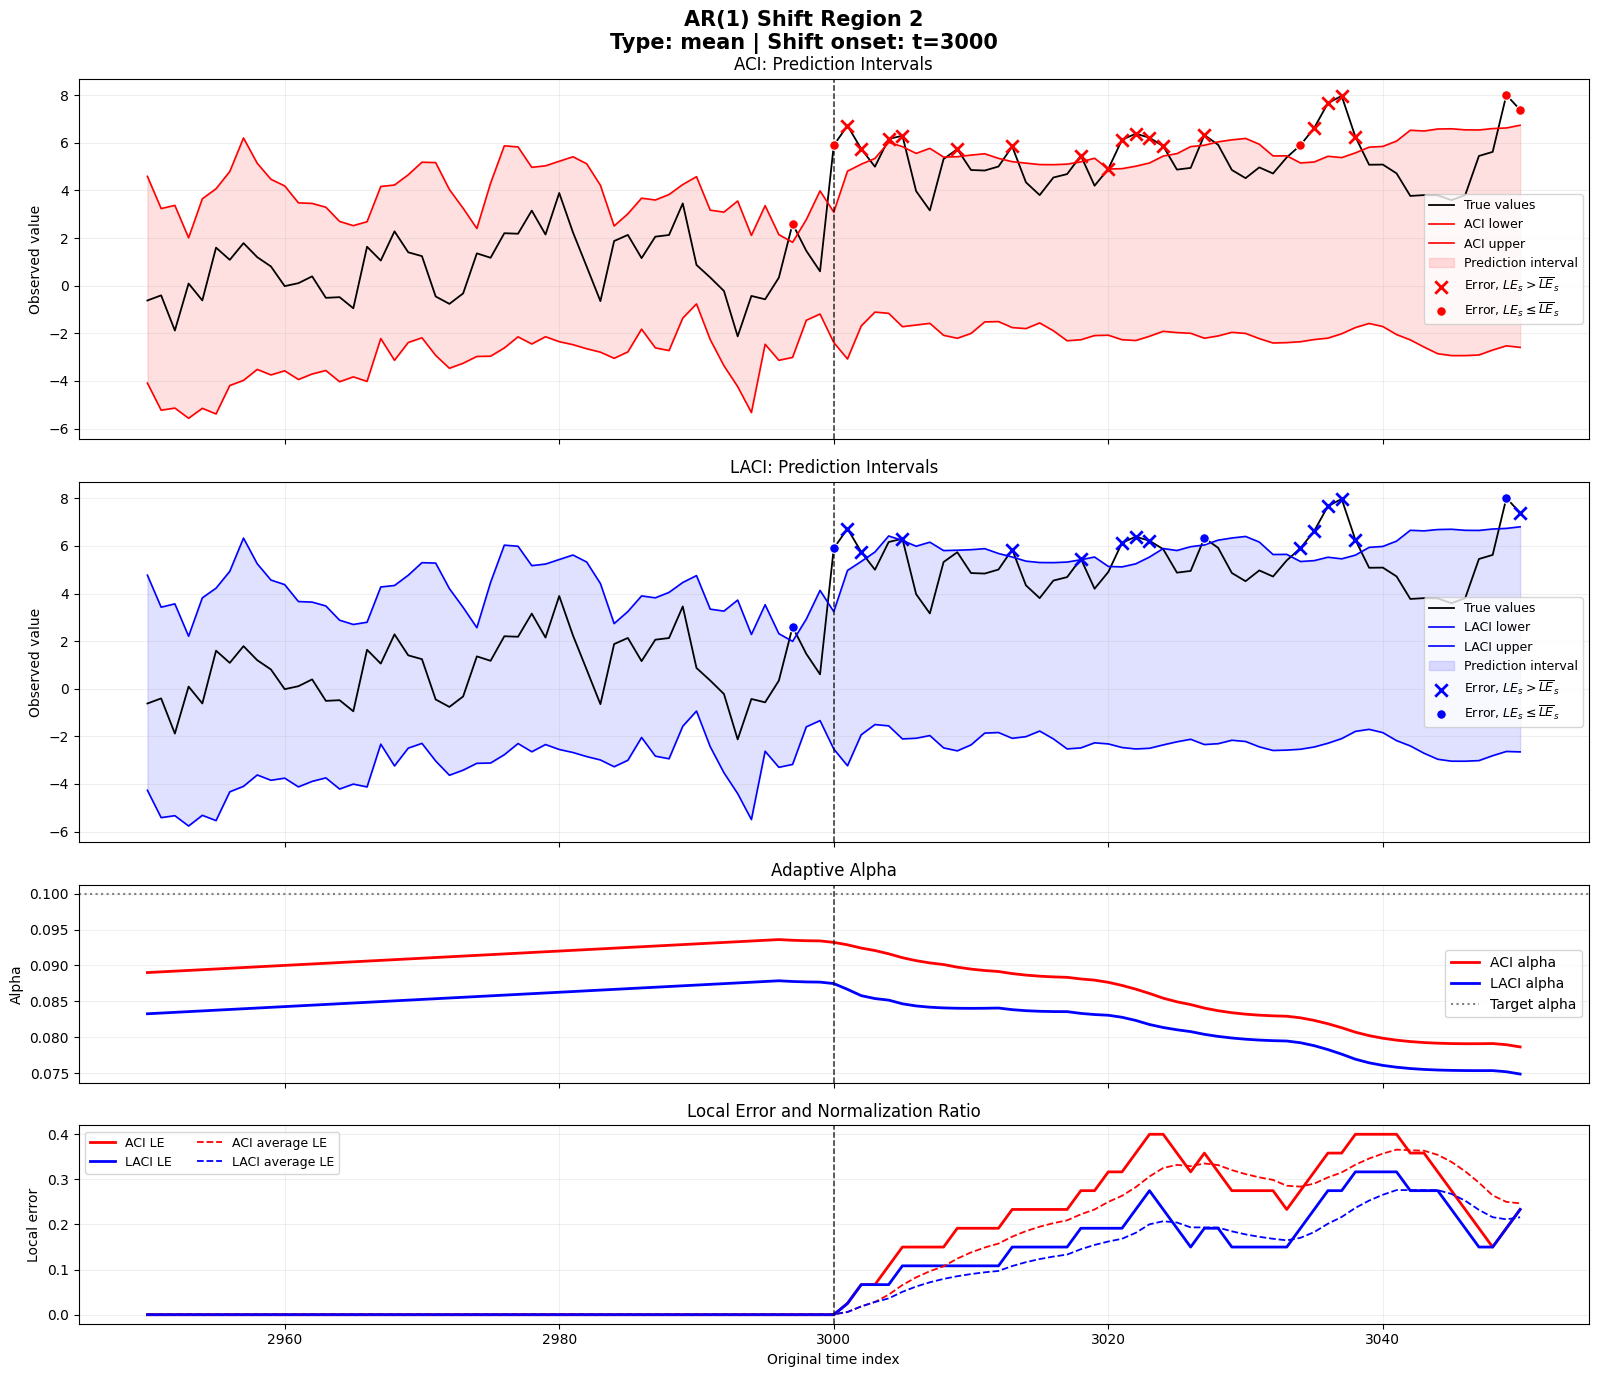


Region 2 (t=3000):
ACI: 17 crosses, 5 dots
LACI: 14 crosses, 4 dots
Saved: ./synthetic_AR1_shift_plots\shift_region_2_t3000.png


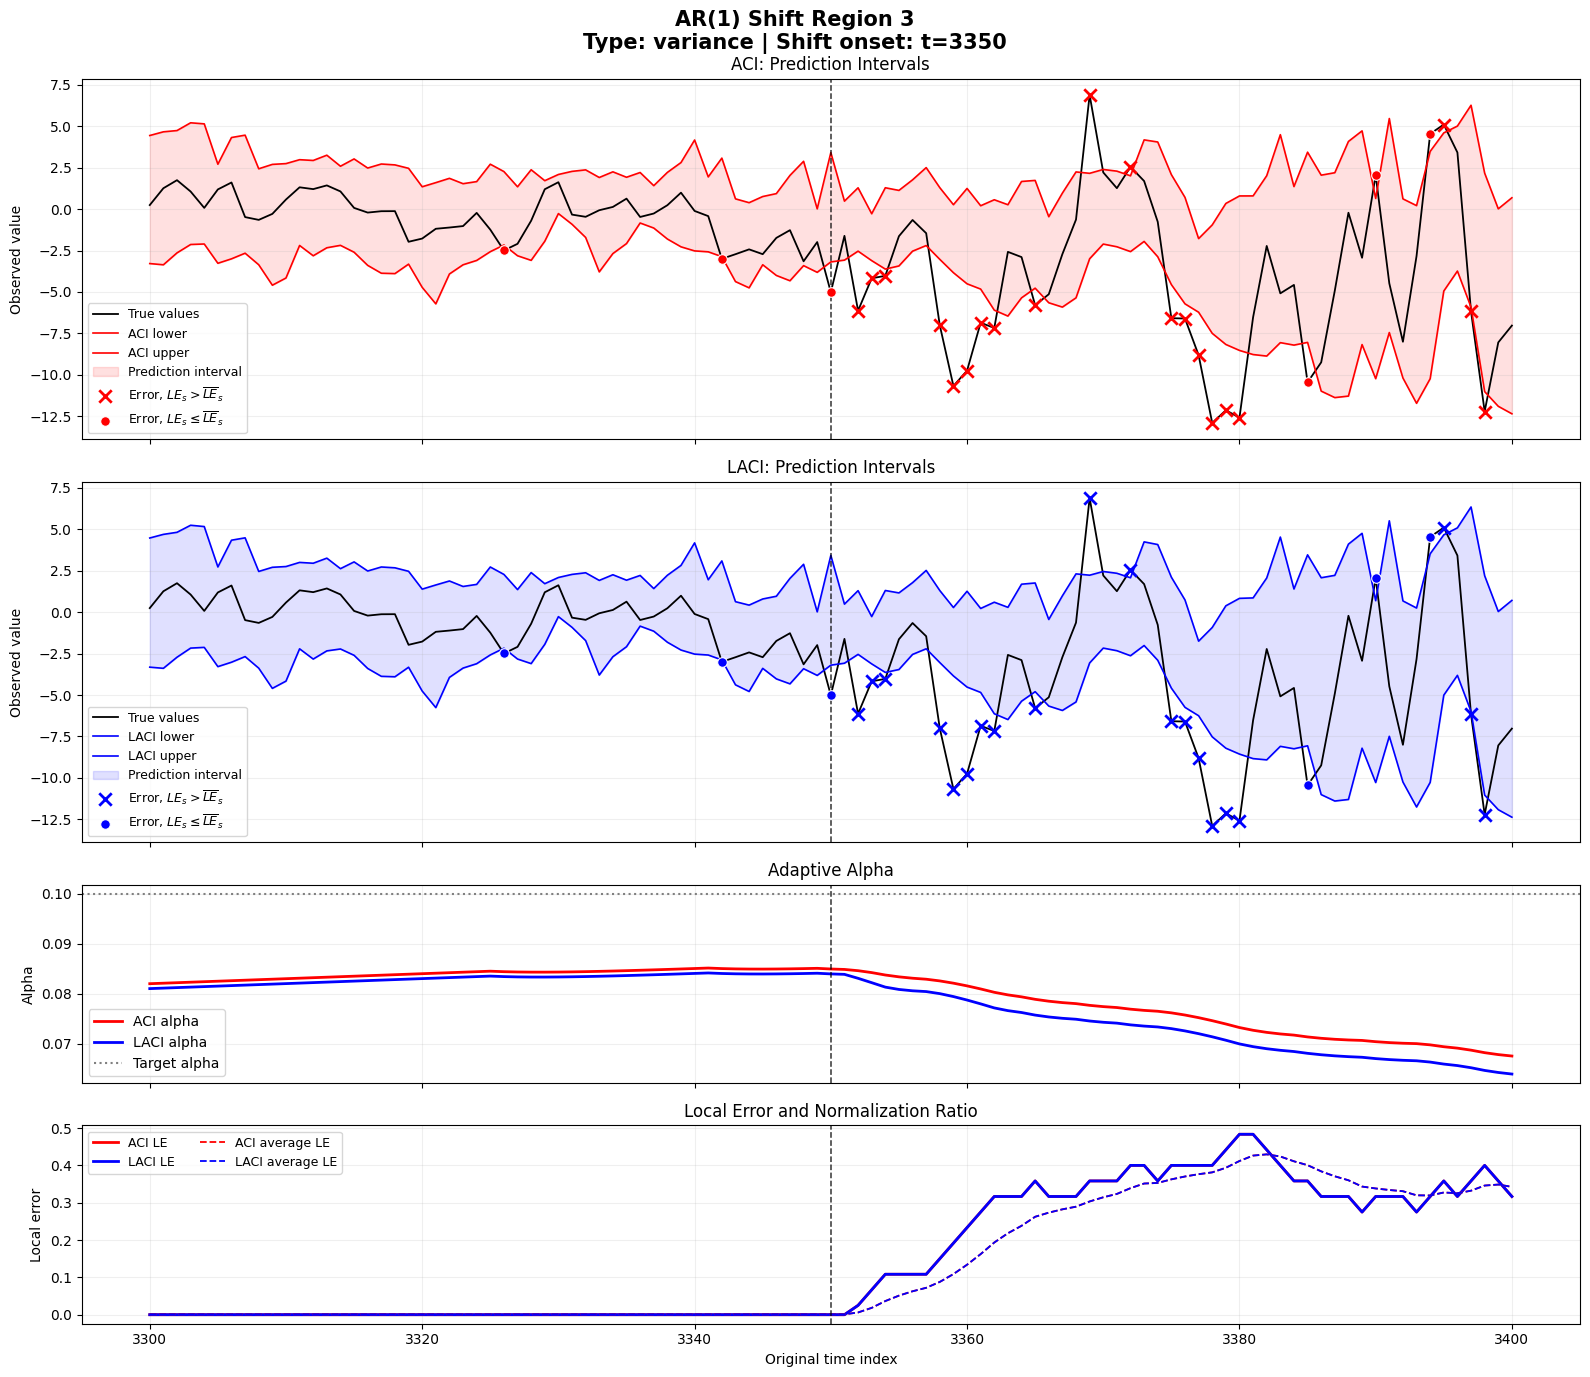


Region 3 (t=3350):
ACI: 20 crosses, 6 dots
LACI: 20 crosses, 6 dots
Saved: ./synthetic_AR1_shift_plots\shift_region_3_t3350.png


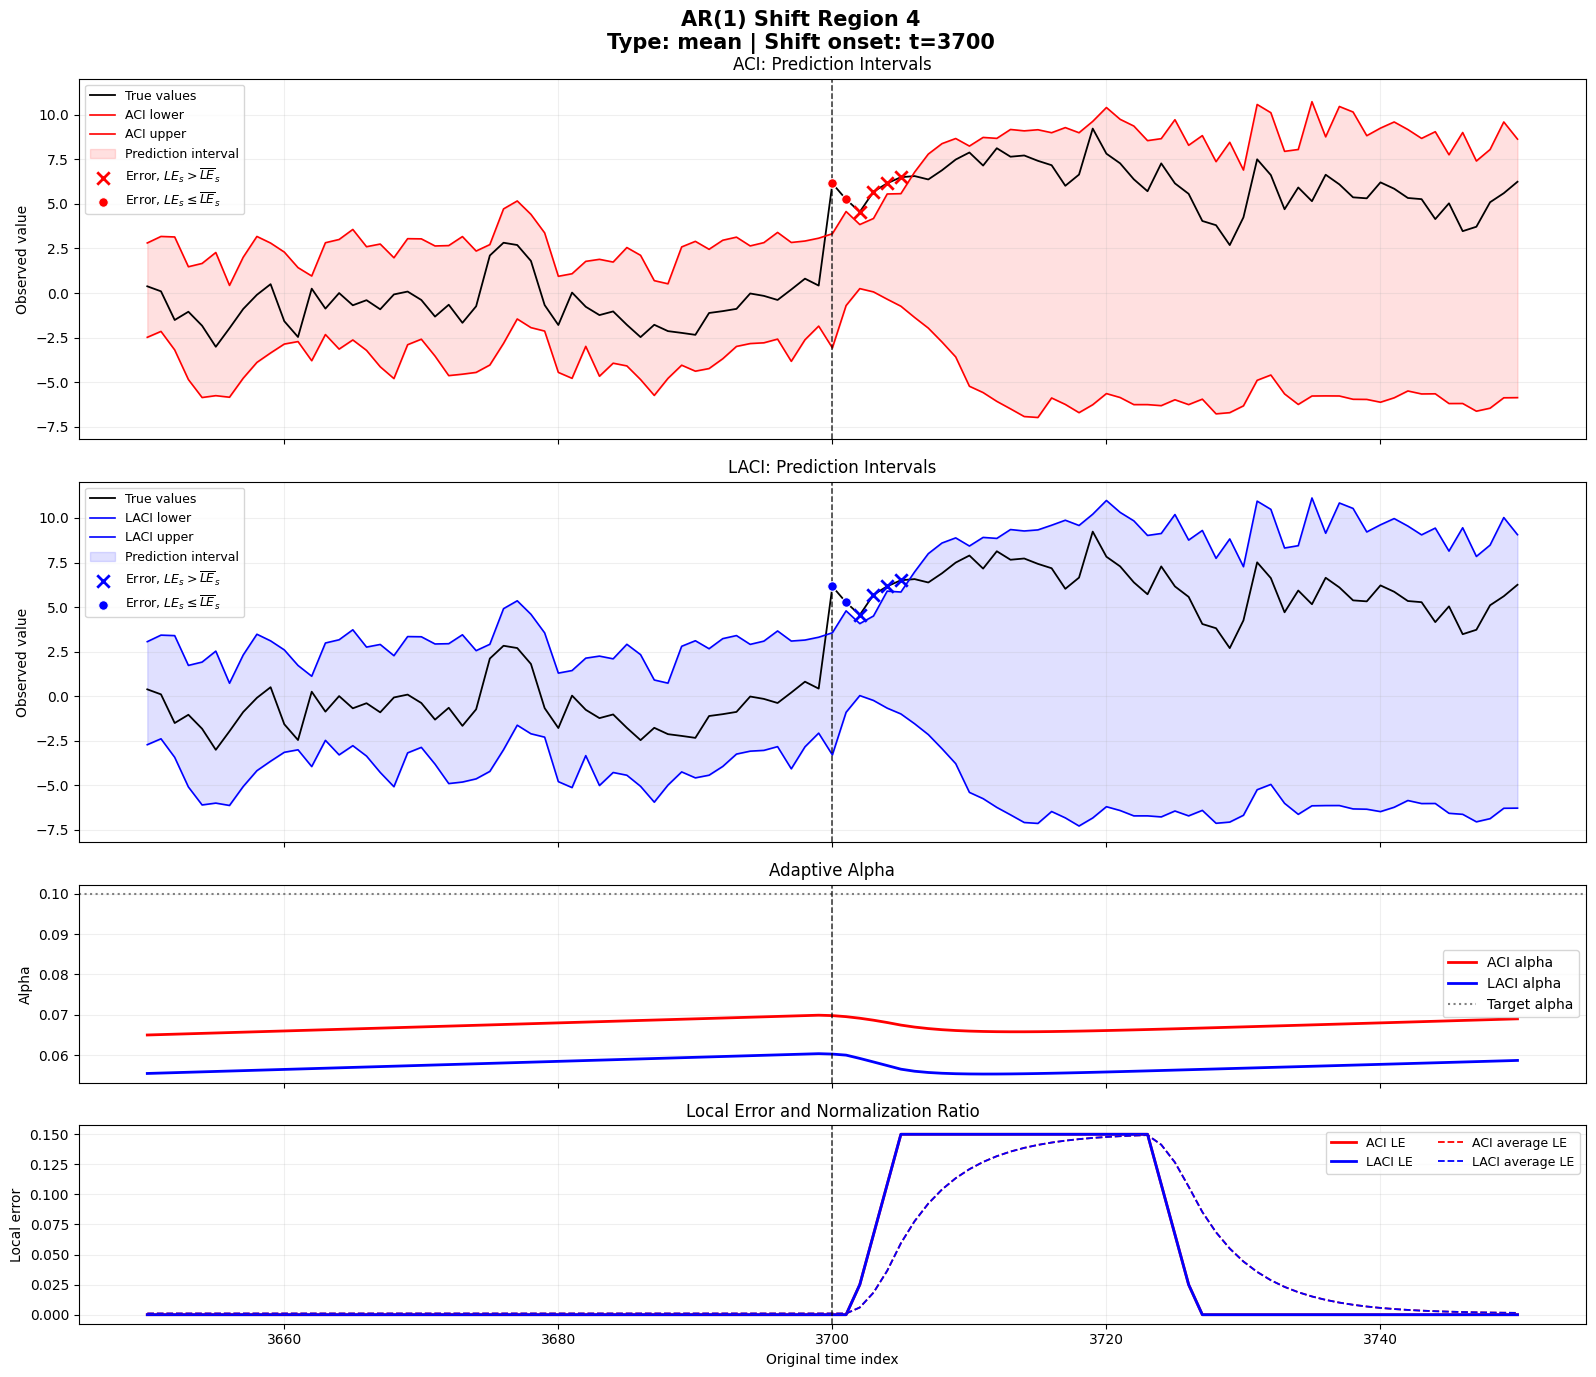


Region 4 (t=3700):
ACI: 4 crosses, 2 dots
LACI: 4 crosses, 2 dots
Saved: ./synthetic_AR1_shift_plots\shift_region_4_t3700.png


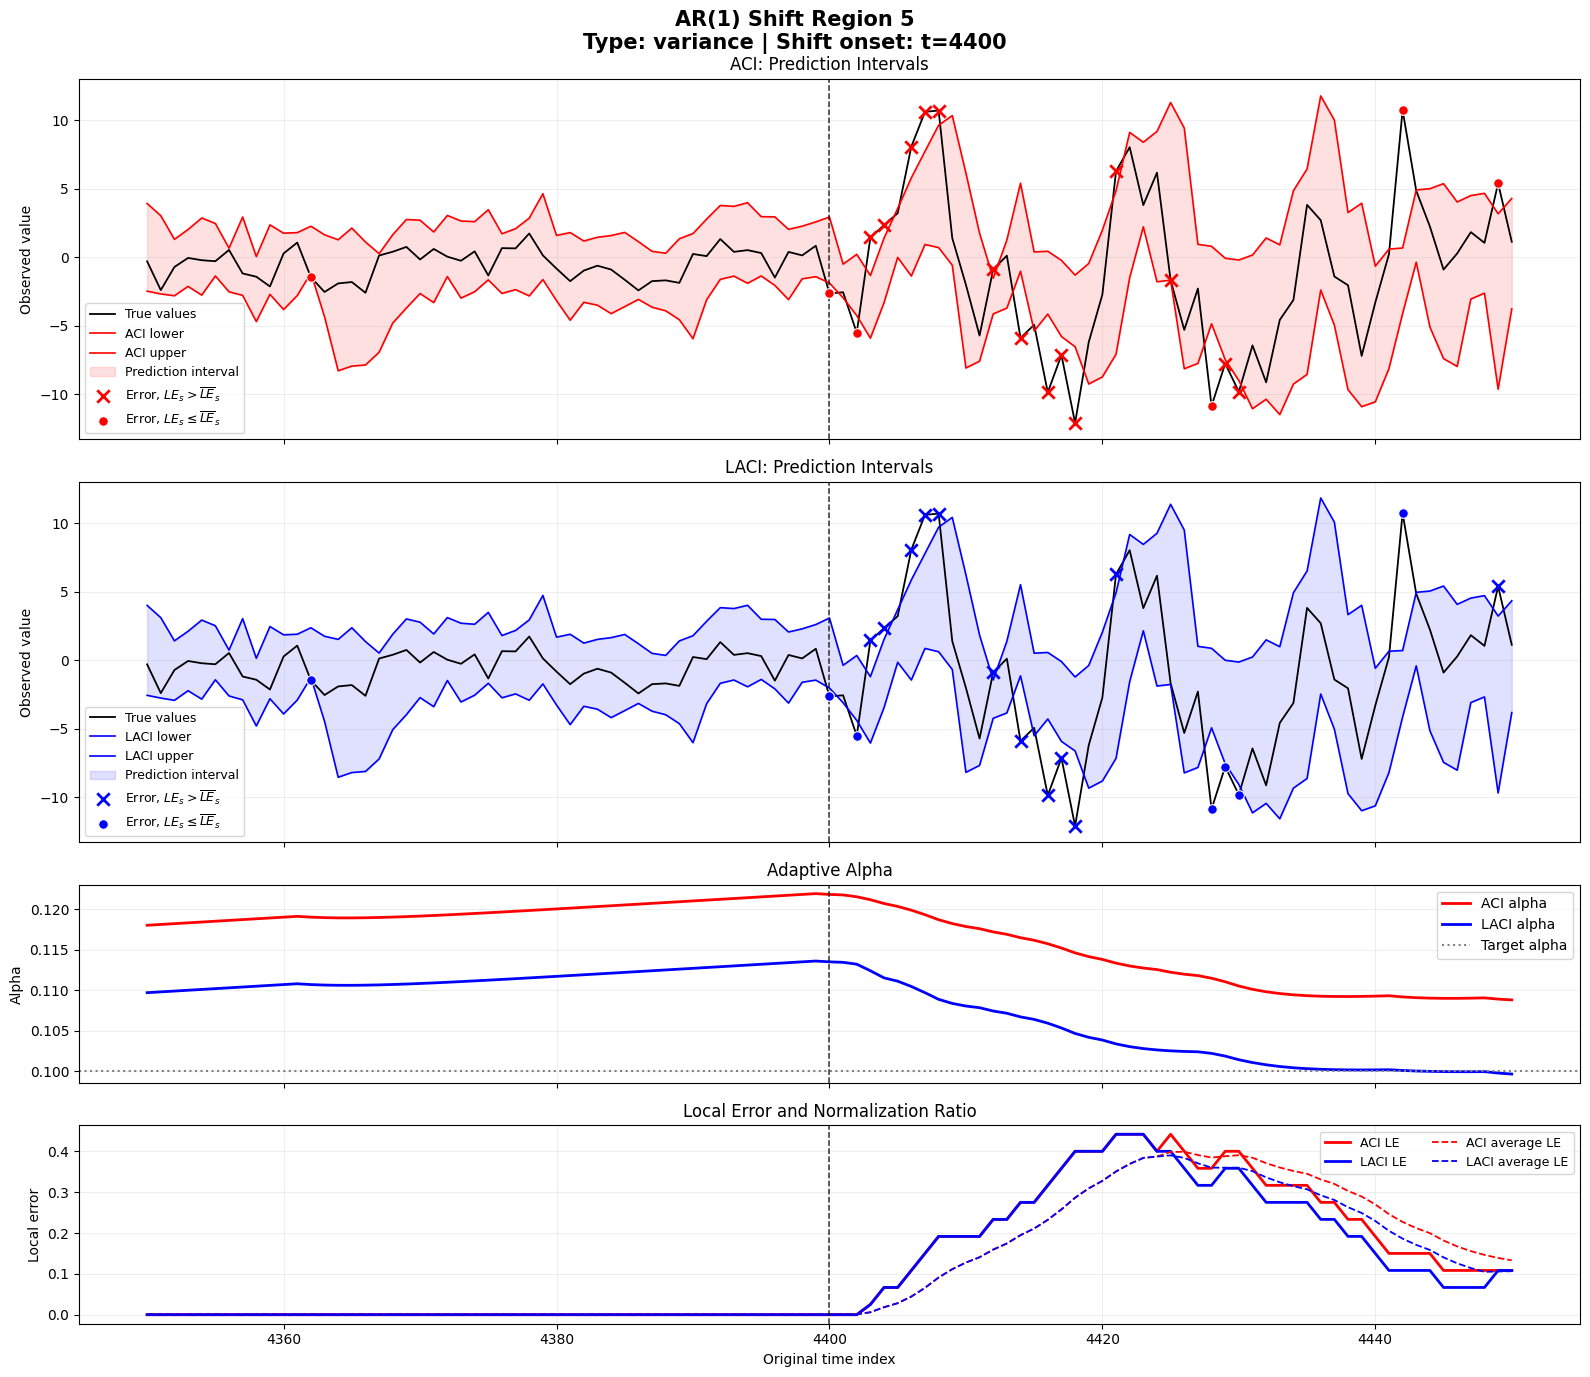


Region 5 (t=4400):
ACI: 14 crosses, 6 dots
LACI: 12 crosses, 7 dots
Saved: ./synthetic_AR1_shift_plots\shift_region_5_t4400.png


In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

SAVE_DIR = "./synthetic_AR1_shift_plots"
os.makedirs(SAVE_DIR, exist_ok=True)

CONTEXT_BEFORE = 50
CONTEXT_AFTER = 50

# ============================================================
# 1. COMPUTE LOCAL ERRORS AND NORMALIZATION RATIOS
# ============================================================

def compute_local_error(errors, window, alpha):
    local_miscoverage = pd.Series(errors).rolling(
        window=window,
        min_periods=window
    ).mean().to_numpy()

    return np.maximum(local_miscoverage - alpha, 0.0)


def compute_bar_LE(local_errors, decay, eps):
    """
    Ratio of normalization constants:

    Z_ACI_s  = sum_k decay^(s-k)
    Z_LACI_s = sum_k decay^(s-k) * (LE_k + eps)

    bar_LE_s = Z_LACI_s / Z_ACI_s
    """
    bar = np.full(len(local_errors), np.nan)

    z_aci = 0.0
    z_laci = 0.0

    for s, le in enumerate(local_errors):

        if not np.isfinite(le):
            continue

        z_aci = decay * z_aci + 1.0
        z_laci = decay * z_laci + (le + eps)

        bar[s] = z_laci / z_aci

    return bar


LE_aci = compute_local_error(
    ACI["errors"], LOCAL_WINDOW, ALPHA
)

LE_laci = compute_local_error(
    LACI["errors"], LOCAL_WINDOW, ALPHA
)

bar_LE_aci = compute_bar_LE(
    LE_aci, DECAY, LACI_EPS
)

bar_LE_laci = compute_bar_LE(
    LE_laci, DECAY, LACI_EPS
)


# ============================================================
# 2. IDENTIFY TWO TYPES OF COVERAGE FAILURES
# ============================================================

def classify_errors(errors, LE, bar_LE):

    error = np.asarray(errors) == 1

    valid = np.isfinite(LE) & np.isfinite(bar_LE)

    # CROSS: error and local error above average
    crosses = error & valid & (LE > bar_LE)

    # DOT: error and local error at/below average
    dots = error & valid & (LE <= bar_LE)

    return crosses, dots


aci_cross, aci_dot = classify_errors(
    ACI["errors"], LE_aci, bar_LE_aci
)

laci_cross, laci_dot = classify_errors(
    LACI["errors"], LE_laci, bar_LE_laci
)


# ============================================================
# 3. CONVERT PREDICTION INTERVALS TO ORIGINAL SCALE
# ============================================================

def inverse_scale(arr):
    return scaler.inverse_transform(
        np.asarray(arr).reshape(-1, 1)
    ).ravel()


y_true = inverse_scale(ACI["actual"])

aci_lower = inverse_scale(ACI["lower"])
aci_upper = inverse_scale(ACI["upper"])

laci_lower = inverse_scale(LACI["lower"])
laci_upper = inverse_scale(LACI["upper"])

assert np.allclose(
    ACI["actual"], LACI["actual"], atol=1e-5
)

# Verify that stored errors match intervals
for method, lower, upper in [
    (ACI, aci_lower, aci_upper),
    (LACI, laci_lower, laci_upper)
]:
    computed_errors = (
        (y_true < lower) | (y_true > upper)
    )

    assert np.array_equal(
        computed_errors,
        np.asarray(method["errors"]) == 1
    ), "Stored errors and prediction intervals disagree"


# ============================================================
# 4. PLOTTING HELPER
# ============================================================

def plot_prediction_intervals(
    ax, xx, yy, lower, upper,
    crosses, dots, color, method_name
):

    # True values
    ax.plot(
        xx, yy,
        color="black",
        linewidth=1.3,
        label="True values",
        zorder=2
    )

    # Lower and upper bounds
    ax.plot(
        xx, lower,
        color=color,
        linewidth=1.2,
        label=f"{method_name} lower"
    )

    ax.plot(
        xx, upper,
        color=color,
        linewidth=1.2,
        label=f"{method_name} upper"
    )

    ax.fill_between(
        xx, lower, upper,
        color=color,
        alpha=0.12,
        label="Prediction interval"
    )

    # CROSS: coverage failure + elevated local error
    ax.scatter(
        xx[crosses],
        yy[crosses],
        marker="x",
        color=color,
        s=80,
        linewidths=2.0,
        zorder=6,
        label=r"Error, $LE_s > \overline{LE}_s$"
    )

    # DOT: coverage failure + local error below average
    ax.scatter(
        xx[dots],
        yy[dots],
        marker="o",
        facecolors=color,
        edgecolors="white",
        linewidths=0.8,
        s=48,
        zorder=6,
        label=r"Error, $LE_s \leq \overline{LE}_s$"
    )

    ax.set_title(f"{method_name}: Prediction Intervals")
    ax.set_ylabel("Observed value")
    ax.grid(alpha=0.2)
    ax.legend(loc="best", fontsize=9)


# ============================================================
# 5. PLOT EACH KNOWN DISTRIBUTION SHIFT
# ============================================================

for region_id, shift in enumerate(shift_records, start=1):

    s = shift["start"]

    mask = (
        (time >= s - CONTEXT_BEFORE)
        & (time <= s + CONTEXT_AFTER)
    )

    xx = time[mask]
    yy = y_true[mask]

    fig, axes = plt.subplots(
        4, 1,
        figsize=(16, 14),
        sharex=True,
        gridspec_kw={
            "height_ratios": [2, 2, 1.1, 1.1]
        }
    )

    # --------------------------------------------------------
    # PANEL 1: ACI (RED)
    # --------------------------------------------------------

    plot_prediction_intervals(
        axes[0],
        xx,
        yy,
        aci_lower[mask],
        aci_upper[mask],
        aci_cross[mask],
        aci_dot[mask],
        "red",
        "ACI"
    )

    # --------------------------------------------------------
    # PANEL 2: LACI (BLUE)
    # --------------------------------------------------------

    plot_prediction_intervals(
        axes[1],
        xx,
        yy,
        laci_lower[mask],
        laci_upper[mask],
        laci_cross[mask],
        laci_dot[mask],
        "blue",
        "LACI"
    )

    # Same y-axis scale for interval comparison
    all_values = np.concatenate([
        yy,
        aci_lower[mask],
        aci_upper[mask],
        laci_lower[mask],
        laci_upper[mask]
    ])

    ymin = np.nanmin(all_values)
    ymax = np.nanmax(all_values)
    pad = max(0.05 * (ymax - ymin), 1e-6)

    axes[0].set_ylim(ymin - pad, ymax + pad)
    axes[1].set_ylim(ymin - pad, ymax + pad)

    # --------------------------------------------------------
    # PANEL 3: ALPHA COMPARISON
    # --------------------------------------------------------

    axes[2].plot(
        xx, ACI["alpha"][mask],
        color="red",
        linewidth=2,
        label="ACI alpha"
    )

    axes[2].plot(
        xx, LACI["alpha"][mask],
        color="blue",
        linewidth=2,
        label="LACI alpha"
    )

    axes[2].axhline(
        ALPHA,
        color="gray",
        linestyle=":",
        label="Target alpha"
    )

    axes[2].set_title("Adaptive Alpha")
    axes[2].set_ylabel("Alpha")
    axes[2].legend()
    axes[2].grid(alpha=0.2)

    # --------------------------------------------------------
    # PANEL 4: LOCAL ERROR COMPARISON
    # --------------------------------------------------------

    axes[3].plot(
        xx, LE_aci[mask],
        color="red",
        linewidth=2,
        label="ACI LE"
    )

    axes[3].plot(
        xx, LE_laci[mask],
        color="blue",
        linewidth=2,
        label="LACI LE"
    )

    axes[3].plot(
        xx, bar_LE_aci[mask],
        color="red",
        linestyle="--",
        linewidth=1.3,
        label="ACI average LE"
    )

    axes[3].plot(
        xx, bar_LE_laci[mask],
        color="blue",
        linestyle="--",
        linewidth=1.3,
        label="LACI average LE"
    )

    axes[3].set_title("Local Error and Normalization Ratio")
    axes[3].set_ylabel("Local error")
    axes[3].set_xlabel("Original time index")
    axes[3].legend(ncol=2, fontsize=9)
    axes[3].grid(alpha=0.2)

    # Mark the known shift onset
    for ax in axes:
        ax.axvline(
            s,
            color="black",
            linestyle="--",
            linewidth=1.1,
            alpha=0.8
        )

    fig.suptitle(
        f"AR(1) Shift Region {region_id}\n"
        f"Type: {shift['type']} | "
        f"Shift onset: t={s}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()

    filename = os.path.join(
        SAVE_DIR,
        f"shift_region_{region_id}_t{s}.png"
    )

    plt.savefig(
        filename,
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()

    # --------------------------------------------------------
    # REPORT MARKER COUNTS
    # --------------------------------------------------------

    print(f"\nRegion {region_id} (t={s}):")

    print(
        f"ACI: {aci_cross[mask].sum()} crosses, "
        f"{aci_dot[mask].sum()} dots"
    )

    print(
        f"LACI: {laci_cross[mask].sum()} crosses, "
        f"{laci_dot[mask].sum()} dots"
    )

    print("Saved:", filename)


In [1]:
"""Five known shifts in a strictly-positive synthetic log-AR(1) series.

Standalone: pip install numpy pandas matplotlib
Run: python ar1_five_shifts_aci_laci.py

Compare recency-weighted ACI against epsilon-stabilized LACI under an
IDENTICAL online setup. Choose the BEST of five pre-defined shift regions
by reduction in mean trailing local error (LPICE). Plot ONLY that region.
A positive improvement means LACI has smaller LPICE. Ties are not wins.
All five outcomes are reported in CSV and terminal, including losses.

The raw signal X_t = exp(Z_t), Z_t = mu + phi*(Z_{t-1}-mu)+sigma_t*noise_t.
Thus X_t > 0, with five changes to the AR(1) innovation variance.
Model: AR(1) regression fitted once on initial log-scale training data;
calibration on rolling, observed log residual scores (no leakage).
"""
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

# ========= SETTINGS =========
SEED = 42
N = 7200
TRAIN_END = 700
CAL_WINDOW = 300
LOCAL_WINDOW = 24
ALPHA = 0.10
GAMMA = 0.003
DECAY = 0.85   # same decay for recency-weighted ACI and LACI
LACI_EPS = 0.001
SHIFT_TIMES = [1800, 2800, 3800, 4800, 5800]
SHIFT_HORIZON = 180  # evaluate [shift, shift+180); selected in advance
PLOT_BEFORE = 70
PLOT_AFTER = 200
# sigma of the innovations in latent log process for each of six regimes
REGIME_SIGMAS = [0.06, 0.17, 0.09, 0.21, 0.10, 0.23]
PHI = 0.8
MU = np.log(50.0)
SAVE_DIR = Path('ar1_five_shift_outputs')
SAVE_DIR.mkdir(parents=True, exist_ok=True)


def generate_series():
    rng = np.random.default_rng(SEED)
    boundaries = [0] + SHIFT_TIMES + [N]
    sigma = np.zeros(N)
    for j, (a, b) in enumerate(zip(boundaries[:-1], boundaries[1:])):
        sigma[a:b] = REGIME_SIGMAS[j]
    z = np.empty(N)
    z[0] = MU
    for t in range(1, N):
        z[t] = MU + PHI * (z[t - 1] - MU) + sigma[t] * rng.normal()
    x = np.exp(z)  # guaranteed strictly positive (up to representable range)
    assert np.isfinite(x).all() and (x > 0).all()
    return x, z, sigma


def fit_ar1_log(z):
    design = np.column_stack([np.ones(TRAIN_END - 1), z[:TRAIN_END - 1]])
    target = z[1:TRAIN_END]
    intercept, phi = np.linalg.lstsq(design, target, rcond=None)[0]
    return float(intercept), float(phi)


def conformal_radius(scores, alpha_level):
    """Exact split-conformal order statistic with full/empty conventions."""
    if alpha_level <= 0:
        return np.inf
    if alpha_level >= 1:
        return -np.inf
    n = len(scores)
    k = int(np.ceil((n + 1) * (1 - alpha_level)))
    if k > n:
        return np.inf
    if k < 1:
        return -np.inf
    return float(np.partition(scores, k - 1)[k - 1])


def make_bounds(point_log, radius):
    if np.isposinf(radius):
        return 0.0, np.inf  # full positive real line
    if np.isneginf(radius):
        return np.inf, 0.0  # empty interval
    return float(np.exp(point_log - radius)), float(np.exp(point_log + radius))


def run_method(x, z, model, method):
    """Time-matched, independent online ACI/LACI adaptation trajectories.

    Both use recency-weighted past error. LACI adds causal, trailing local LE.
    Forecast -> observe -> local error -> weighted alpha update.
    """
    assert method in ('ACI', 'LACI')
    intercept, phi = model
    point_log = intercept + phi * z[:-1]
    prior_residual_scores = np.abs(z[1:TRAIN_END] - point_log[:TRAIN_END - 1]).tolist()
    # Historical residual scores may be used only once their outcomes occurred.
    alpha_t = ALPHA
    numerator = 0.0
    denominator = 0.0
    coverage_history = []
    rows = []
    for t in range(TRAIN_END, N):
        scores = np.asarray(prior_residual_scores[-CAL_WINDOW:], dtype=float)
        radius = conformal_radius(scores, alpha_t)
        pred_log = intercept + phi * z[t - 1]
        lower, upper = make_bounds(pred_log, radius)
        err = int(not (lower <= x[t] <= upper))
        coverage_history.append(1 - err)
        if len(coverage_history) >= LOCAL_WINDOW:
            lp = float(np.mean(coverage_history[-LOCAL_WINDOW:]))
            le = max((1 - ALPHA) - lp, 0.0)
        else:
            lp, le = np.nan, 0.0  # explicit early-step convention
        magnitude = 1.0 if method == 'ACI' else le + LACI_EPS
        numerator = DECAY * numerator + magnitude * err
        denominator = DECAY * denominator + magnitude
        weighted_err = numerator / denominator
        used_alpha = alpha_t
        alpha_t = alpha_t + GAMMA * (ALPHA - weighted_err)
        rows.append((t, x[t], lower, upper, err, lp, le if np.isfinite(lp) else np.nan,
                     used_alpha, alpha_t, weighted_err))
        prior_residual_scores.append(abs(z[t] - pred_log))
    return pd.DataFrame(rows, columns=['t', 'y', 'lower', 'upper', 'err', 'LPICP',
                                      'LE', 'alpha_used', 'alpha_next', 'weighted_error']).set_index('t')


def describe_shift(df_aci, df_laci, shift):
    # Evaluate the same 180 target timestamps for both methods.
    a = df_aci.loc[shift:shift + SHIFT_HORIZON - 1]
    b = df_laci.loc[shift:shift + SHIFT_HORIZON - 1]
    assert len(a) == len(b) == SHIFT_HORIZON
    mean_a, mean_b = a['LE'].mean(), b['LE'].mean()
    return {
        'shift_time': shift,
        'sigma_before': REGIME_SIGMAS[SHIFT_TIMES.index(shift)],
        'sigma_after': REGIME_SIGMAS[SHIFT_TIMES.index(shift) + 1],
        'n_steps': SHIFT_HORIZON,
        'ACI_PICP': 1 - a['err'].mean(),
        'LACI_PICP': 1 - b['err'].mean(),
        'ACI_mean_LE': mean_a,
        'LACI_mean_LE': mean_b,
        'LE_improvement_ACI_minus_LACI': mean_a - mean_b,
        'LACI_win': bool(mean_b < mean_a - 1e-12),
        'ACI_mean_width': float((a['upper'] - a['lower']).mean()),
        'LACI_mean_width': float((b['upper'] - b['lower']).mean()),
        'ACI_failure_points_LE_above_running_bar': np.nan,  # filled separately
    }


def running_le_baseline(le):
    values = le.to_numpy(float)
    out = np.full(len(values), np.nan)
    numerator = denominator = 0.0
    for j, v in enumerate(values):
        if np.isfinite(v):
            numerator = DECAY * numerator + v  # NO epsilon in LEbar
            denominator = DECAY * denominator + 1.0
            out[j] = numerator / denominator
    return pd.Series(out, index=le.index)


def plot_best_shift(x, sigma, aci, laci, row):
    shift = int(row['shift_time'])
    left = max(TRAIN_END + LOCAL_WINDOW - 1, shift - PLOT_BEFORE)
    right = min(N - 1, shift + PLOT_AFTER)
    a, b = aci.loc[left:right], laci.loc[left:right]
    tt = a.index.to_numpy()
    fig, axes = plt.subplots(4, 1, figsize=(14, 13), sharex=True,
                             gridspec_kw={'height_ratios': [1.2, 2, 2, 1.3]})
    # 1: positive series and known shift.
    axes[0].plot(tt, x[tt], color='#222222', lw=1.3, label='Positive AR(1) data')
    axes[0].set_ylabel('Observation')
    axes[0].set_title('Positive AR(1) series around the known distribution shift')
    axes[0].legend(loc='upper left')

    # 2-3: match requested figure theme: ACI in red, LACI in blue.
    # Lower and upper bounds have distinct shades within each method.
    palettes = {
        'ACI': dict(lower='#b91c1c', upper='#fb4b3a', fill='#ef4444', failure='#dc2626'),
        'LACI': dict(lower='#1d4ed8', upper='#06b6d4', fill='#60a5fa', failure='#1d4ed8'),
    }
    for ax, d, method in ((axes[1], a, 'ACI'), (axes[2], b, 'LACI')):
        colors = palettes[method]
        ax.plot(tt, d['y'].to_numpy(), color='black', lw=1.5,
                label='True values', zorder=4)
        ax.plot(tt, d['lower'].to_numpy(), color=colors['lower'], lw=1.4,
                label=f'{method} lower bound')
        ax.plot(tt, d['upper'].to_numpy(), color=colors['upper'], lw=1.4,
                label=f'{method} upper bound')
        ax.fill_between(tt, d['lower'].to_numpy(), d['upper'].to_numpy(),
                        color=colors['fill'], alpha=0.15, label='Prediction interval')
        failures = d['err'].to_numpy() == 1
        ax.scatter(tt[failures], d['y'].to_numpy()[failures], marker='x',
                   color=colors['failure'], s=48, linewidth=1.7,
                   label='Coverage failure', zorder=5)
        ax.set_title(f'{method}: Prediction Intervals')
        ax.set_ylabel('Observed value')
        ax.legend(ncol=2, fontsize=9, loc='upper left')

    # Equal vertical scales for comparing actual width and prediction failures.
    vals = np.concatenate([a['y'].to_numpy(), a['lower'].to_numpy(),a['upper'].to_numpy(),
                           b['lower'].to_numpy(), b['upper'].to_numpy()])
    finite = vals[np.isfinite(vals)]
    low, high = float(np.min(finite)), float(np.max(finite))
    pad = .05 * (high-low) if high > low else 1.0
    for ax in axes[1:3]:
        ax.set_ylim(max(0, low-pad), high+pad)

    # 4: realized trailing LE comparison ONLY (no average LE baseline).
    axes[3].plot(tt, a['LE'].to_numpy(), color='#dc2626', lw=2.1,
                 label=r'ACI $LE_t^{(L)}$')
    axes[3].plot(tt, b['LE'].to_numpy(), color='#1d4ed8', lw=2.1,
                 label=r'LACI $LE_t^{(L)}$')
    axes[3].set(ylabel='Local undercoverage', xlabel='Original time index')
    axes[3].legend(ncol=2, fontsize=9, loc='upper left')
    for ax in axes:
        ax.axvline(shift, color='black', ls='--', lw=1, alpha=.8)
        ax.axvspan(shift, shift + SHIFT_HORIZON - 1, color='#fde68a', alpha=.1)
        ax.grid(alpha=.18)
    fig.suptitle(f'Best of 5 predefined AR(1) shifts: t={shift} | '
                 f'ACI mean LE={row["ACI_mean_LE"]:.4f}, '
                 f'LACI mean LE={row["LACI_mean_LE"]:.4f}', fontsize=15)
    fig.tight_layout(rect=(0,0,1,.97))
    target = SAVE_DIR / 'best_shift_ACI_vs_LACI.png'
    fig.savefig(target, dpi=220, bbox_inches='tight')
    plt.close(fig)
    return target


def main():
    x, z, sigma = generate_series()
    fitted = fit_ar1_log(z)
    aci = run_method(x, z, fitted, 'ACI')
    laci = run_method(x, z, fitted, 'LACI')
    assert np.allclose(aci['y'], laci['y'])
    for df in (aci, laci):
        check = ((df['y'] < df['lower']) | (df['y'] > df['upper'])).astype(int)
        assert np.array_equal(check.to_numpy(), df['err'].to_numpy())
        assert (df['y'] > 0).all()
        assert (df['lower'] >= 0).all() and (df['upper'] >= 0).all()
        df['LEbar'] = running_le_baseline(df['LE'])
    rows = [describe_shift(aci, laci, s) for s in SHIFT_TIMES]
    for row in rows:
        idx = int(row['shift_time'])
        a = aci.loc[idx:idx+SHIFT_HORIZON-1]
        failures = a[(a['err']==1)&a['LE'].notna()]
        row['ACI_failure_points_LE_above_running_bar'] = (
            float((failures['LE'] > failures['LEbar']).mean()) if len(failures) else np.nan
        )
    results = pd.DataFrame(rows)
    # Predefined criterion; choose best among all five, whether or not a win.
    best = results.sort_values(['LE_improvement_ACI_minus_LACI','shift_time'],
                               ascending=[False, True]).iloc[0]
    results.to_csv(SAVE_DIR / 'all_five_shift_scores.csv', index=False)
    aci.to_csv(SAVE_DIR / 'aci_trajectory.csv')
    laci.to_csv(SAVE_DIR / 'laci_trajectory.csv')
    figure = plot_best_shift(x, sigma, aci, laci, best)
    print('\n=== All FIVE predefined shift regions (LPICE is lower-is-better) ===')
    print(results.to_string(index=False, float_format=lambda v: f'{v:.5f}'))
    print(f'\nLACI wins: {int(results["LACI_win"].sum())}/5')
    print(f'Best shift by mean local-error reduction: t={int(best["shift_time"])}')
    print(f'Best improvement: {best["LE_improvement_ACI_minus_LACI"]:+.5f}')
    print('One plot saved:', figure)
    return results


if __name__ == '__main__':
    main()



=== All FIVE predefined shift regions (LPICE is lower-is-better) ===
 shift_time  sigma_before  sigma_after  n_steps  ACI_PICP  LACI_PICP  ACI_mean_LE  LACI_mean_LE  LE_improvement_ACI_minus_LACI  LACI_win  ACI_mean_width  LACI_mean_width  ACI_failure_points_LE_above_running_bar
       1800       0.06000      0.17000      180   0.79444    0.85556      0.12481       0.07310                        0.05171      True        20.51464         23.42089                                  0.78378
       2800       0.17000      0.09000      180   0.97778    0.98333      0.00069       0.00000                        0.00069      True        23.13111         24.42301                                  0.25000
       3800       0.09000      0.21000      180   0.80000    0.87222      0.12250       0.06528                        0.05722      True        27.35197         34.54463                                  0.72222
       4800       0.21000      0.10000      180   0.99444    0.99444      0.00181     